# SECTION 1 - Imports and configuration
Research-grade, leakage-aware network traffic forecasting pipeline for 5G/6G and IoT data.

In [1]:
import os
import re
import time
import json
import math
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, IsolationForest
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
AGG_FREQ = '1s'
EXPERIMENT_NAME = '5G_6G_Network_Traffic_Forecasting'

try:
    import snowflake.connector
    from snowflake.connector.pandas_tools import write_pandas
except Exception:
    snowflake = None

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout, LSTM, GRU
except Exception:
    tf = None

try:
    import mlflow
    import mlflow.sklearn
    import mlflow.tensorflow
except Exception:
    mlflow = None

Initializes reproducible imports, metrics, and optional Snowflake, TensorFlow, and MLflow dependencies safely.

# SECTION 2 - Snowflake data loading

In [4]:
SNOWFLAKE_CONFIG = {
    'user': os.getenv('SNOWFLAKE_USER'),
    'password': os.getenv('SNOWFLAKE_PASSWORD'),
    'account': os.getenv('SNOWFLAKE_ACCOUNT'),
    'warehouse': os.getenv('SNOWFLAKE_WAREHOUSE', 'COMPUTE_WH'),
    'database': os.getenv('SNOWFLAKE_DATABASE', 'NETWORK_ANALYTICS'),
    'schema': os.getenv('SNOWFLAKE_SCHEMA', 'PUBLIC'),
}

RAW_TABLE = 'ZOOM_1'
ANOM_TABLE = 'ZOOM_ANOMALIES'
RAW_COLUMNS = ['NO', 'TIME', 'SOURCE', 'DESTINATION', 'PROTOCOL', 'LENGTH']

def get_snowflake_connection(config: dict):
    if snowflake is None:
        raise ImportError('snowflake-connector-python is not installed in this environment.')
    missing = [k for k, v in config.items() if v in [None, '']]
    if missing:
        raise ValueError(f'Missing Snowflake credentials: {missing}')
    return snowflake.connector.connect(**config)

def load_network_data(source='snowflake', csv_path='Zoom_1.csv', max_rows=None):
    if source == 'csv':
        downloads_path = os.path.join(os.path.expanduser('~'), 'Downloads', csv_path)
        candidate_paths = [csv_path, downloads_path]
        resolved_path = next((path for path in candidate_paths if os.path.isfile(path)), None)
        if resolved_path is None:
            nested_path = os.path.join(downloads_path, os.path.basename(csv_path))
            resolved_path = nested_path if os.path.isfile(nested_path) else None
        if resolved_path is None:
            raise FileNotFoundError(f'Could not locate CSV in: {candidate_paths}')
        df = pd.read_csv(resolved_path)
    else:
        conn = get_snowflake_connection(SNOWFLAKE_CONFIG)
        try:
            query = f"SELECT NO, TIME, SOURCE, DESTINATION, PROTOCOL, LENGTH FROM {SNOWFLAKE_CONFIG['database']}.{SNOWFLAKE_CONFIG['schema']}.{RAW_TABLE}"
            if max_rows is not None:
                query += f' LIMIT {int(max_rows)}'
            df = pd.read_sql(query, conn)
        finally:
            conn.close()

    df.columns = [c.replace('.', '').strip().upper() for c in df.columns]
    return df

# Use source='snowflake' for the full run; CSV is the reproducible local fallback.
df_raw = load_network_data(source='csv', csv_path='Zoom_1.csv', max_rows=None)
print(df_raw.shape)
df_raw.head()

(6095138, 7)


,NO,TIME,SOURCE,DESTINATION,PROTOCOL,LENGTH,INFO
0,2,2022-05-30 16:01:36.328035,192.0.0.2,144.195.34.97,UDP,936,47018 > 8801 Len=908
1,3,2022-05-30 16:01:36.332697,192.0.0.2,144.195.34.97,UDP,593,47018 > 8801 Len=565
2,4,2022-05-30 16:01:36.332777,192.0.0.2,144.195.34.97,UDP,593,47018 > 8801 Len=565
3,5,2022-05-30 16:01:36.332821,192.0.0.2,144.195.34.97,UDP,592,47018 > 8801 Len=564
4,6,2022-05-30 16:01:36.332849,192.0.0.2,144.195.34.97,UDP,592,47018 > 8801 Len=564


Loads packet-level data from Snowflake or CSV while preserving original columns for reproducible research.

# SECTION 3 - Dataset description

In [5]:
def describe_dataset(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    duplicates = int(df.duplicated().sum())

    summary = pd.DataFrame({
        'rows': [len(df)],
        'columns': [df.shape[1]],
        'memory_mb': [round(memory_mb, 3)],
        'duplicate_rows': [duplicates],
    })

    col_summary = pd.DataFrame({
        'column': df.columns,
        'dtype': [str(df[c].dtype) for c in df.columns],
        'unique_values': [df[c].nunique(dropna=True) for c in df.columns],
        'missing_values': [df[c].isna().sum() for c in df.columns],
    })
    col_summary['missing_pct'] = (col_summary['missing_values'] / len(df) * 100).round(4)

    return summary, col_summary

dataset_summary, column_summary = describe_dataset(df_raw)
display(dataset_summary)
display(column_summary)

feature_documentation = pd.DataFrame({
    'feature': RAW_COLUMNS,
    'description_from_available_data': [
        'Packet sequence/index field as provided by source.',
        'Packet capture timestamp field from source data.',
        'Source endpoint identifier string from capture.',
        'Destination endpoint identifier string from capture.',
        'Protocol label provided in source record.',
        'Packet length value from source record.'
    ]
})
display(feature_documentation)

,rows,columns,memory_mb,duplicate_rows
0,6095138,7,1959.107,0


,column,dtype,unique_values,missing_values,missing_pct
0,NO,int64,6095138,0,0.0
1,TIME,object,6095138,0,0.0
2,SOURCE,object,4,0,0.0
3,DESTINATION,object,5,0,0.0
4,PROTOCOL,object,4,0,0.0
5,LENGTH,int64,1229,0,0.0
6,INFO,object,6799,0,0.0


,feature,description_from_available_data
0,NO,Packet sequence/index field as provided by sou...
1,TIME,Packet capture timestamp field from source data.
2,SOURCE,Source endpoint identifier string from capture.
3,DESTINATION,Destination endpoint identifier string from ca...
4,PROTOCOL,Protocol label provided in source record.
5,LENGTH,Packet length value from source record.


Summarizes dimensions, dtypes, uniqueness, missingness, and duplicates to anchor later preprocessing decisions quantitatively.

# SECTION 4 - Timestamp analysis

In [6]:
def validate_timestamps(df: pd.DataFrame, time_col='TIME'):
    out = df.copy()
    out['TIME_PARSED'] = pd.to_datetime(out[time_col], errors='coerce')

    invalid_count = out['TIME_PARSED'].isna().sum()
    parsed = out.dropna(subset=['TIME_PARSED']).copy()

    parsed = parsed.sort_values('TIME_PARSED')
    diffs = parsed['TIME_PARSED'].diff().dropna()

    report = {
        'invalid_timestamps': int(invalid_count),
        'valid_timestamps': int(parsed.shape[0]),
        'min_timestamp': parsed['TIME_PARSED'].min() if not parsed.empty else pd.NaT,
        'max_timestamp': parsed['TIME_PARSED'].max() if not parsed.empty else pd.NaT,
        'unique_timestamps': int(parsed['TIME_PARSED'].nunique()),
        'duplicate_timestamps': int(parsed['TIME_PARSED'].duplicated().sum()),
        'chronologically_sorted': bool(parsed['TIME_PARSED'].is_monotonic_increasing),
        'min_time_diff': diffs.min() if not diffs.empty else pd.NaT,
        'median_time_diff': diffs.median() if not diffs.empty else pd.NaT,
        'max_time_diff': diffs.max() if not diffs.empty else pd.NaT,
    }

    if pd.notna(report['min_timestamp']) and pd.notna(report['max_timestamp']):
        report['temporal_coverage'] = report['max_timestamp'] - report['min_timestamp']
    else:
        report['temporal_coverage'] = pd.NaT

    return out, pd.DataFrame([report])

df_time, timestamp_report = validate_timestamps(df_raw, time_col='TIME')
display(timestamp_report)
print('Invalid timestamp rows (first 5):')
display(df_time[df_time['TIME_PARSED'].isna()].head())

,invalid_timestamps,valid_timestamps,min_timestamp,max_timestamp,unique_timestamps,duplicate_timestamps,chronologically_sorted,min_time_diff,median_time_diff,max_time_diff,temporal_coverage
0,0,6095138,2022-05-30 16:01:36.328035,2022-05-30 21:54:00.660533,6095138,0,True,0 days 00:00:00.000011,0 days 00:00:00.001075,0 days 00:00:00.041736,0 days 05:52:24.332498


Invalid timestamp rows (first 5):


,NO,TIME,SOURCE,DESTINATION,PROTOCOL,LENGTH,INFO,TIME_PARSED


Converts timestamps once, quantifies parsing failures, and characterizes temporal continuity without silently dropping records.

# SECTION 5 - Data quality assessment

In [7]:
def _valid_ipv4_like(series: pd.Series) -> pd.Series:
    pattern = r'^(?:\d{1,3}\.){3}\d{1,3}(?::\d+)?$'
    return series.astype(str).str.match(pattern, na=False)

def assess_data_quality(df: pd.DataFrame) -> pd.DataFrame:
    n = len(df)
    q = []

    def add_issue(name, mask_or_count, action):
        count = int(mask_or_count.sum()) if hasattr(mask_or_count, 'sum') else int(mask_or_count)
        q.append({
            'issue': name,
            'count': count,
            'percentage': round((count / n * 100) if n else 0.0, 4),
            'recommended_action': action
        })

    add_issue('missing_TIME', df['TIME'].isna(), 'Inspect source formatting; parse and quarantine invalid timestamps.')
    add_issue('invalid_TIME_after_parse', df['TIME_PARSED'].isna(), 'Keep flagged rows for audit before cleaning.')
    add_issue('missing_SOURCE', df['SOURCE'].isna(), 'Check capture pipeline and endpoint metadata.')
    add_issue('missing_DESTINATION', df['DESTINATION'].isna(), 'Check capture pipeline and endpoint metadata.')
    add_issue('missing_PROTOCOL', df['PROTOCOL'].isna(), 'Mark as UNKNOWN category if retained.')

    length_num = pd.to_numeric(df['LENGTH'], errors='coerce')
    add_issue('non_numeric_LENGTH', length_num.isna(), 'Coerce to numeric and investigate parser failures.')
    add_issue('negative_LENGTH', (length_num < 0).fillna(False), 'Treat as data error; exclude if confirmed invalid.')
    add_issue('zero_LENGTH', (length_num == 0).fillna(False), 'Retain but track as potential idle/control traffic.')

    add_issue('duplicate_rows', df.duplicated(), 'Review duplicates by timestamp and packet identifiers before dropping.')

    src_valid = _valid_ipv4_like(df['SOURCE'])
    dst_valid = _valid_ipv4_like(df['DESTINATION'])
    add_issue('invalid_SOURCE_format', ~src_valid, 'Retain as unknown endpoint format; investigate parser assumptions.')
    add_issue('invalid_DESTINATION_format', ~dst_valid, 'Retain as unknown endpoint format; investigate parser assumptions.')

    protocol_clean = df['PROTOCOL'].astype(str).str.upper().str.strip()
    expected_protocols = {'UDP', 'TCP', 'WIREGUARD', 'ICMP', 'TLS', 'HTTP', 'HTTPS'}
    unexpected_protocol = ~protocol_clean.isin(expected_protocols)
    add_issue('unexpected_PROTOCOL_values', unexpected_protocol, 'Validate vocabulary; map rare labels to standardized taxonomy if justified.')

    suspicious_ts = df['TIME_PARSED'].notna() & (
        (df['TIME_PARSED'].dt.year < 2000) | (df['TIME_PARSED'].dt.year > 2100)
    )
    add_issue('suspicious_timestamps', suspicious_ts, 'Inspect source timezone and parser assumptions.')

    return pd.DataFrame(q).sort_values(['count', 'issue'], ascending=[False, True]).reset_index(drop=True)

quality_report = assess_data_quality(df_time)
display(quality_report)

,issue,count,percentage,recommended_action
0,unexpected_PROTOCOL_values,2539,0.0417,Validate vocabulary; map rare labels to standa...
1,duplicate_rows,0,0.0000,Review duplicates by timestamp and packet iden...
2,invalid_DESTINATION_format,0,0.0000,Retain as unknown endpoint format; investigate...
3,invalid_SOURCE_format,0,0.0000,Retain as unknown endpoint format; investigate...
4,invalid_TIME_after_parse,0,0.0000,Keep flagged rows for audit before cleaning.
5,missing_DESTINATION,0,0.0000,Check capture pipeline and endpoint metadata.
6,missing_PROTOCOL,0,0.0000,Mark as UNKNOWN category if retained.
7,missing_SOURCE,0,0.0000,Check capture pipeline and endpoint metadata.
8,missing_TIME,0,0.0000,Inspect source formatting; parse and quarantin...
9,negative_LENGTH,0,0.0000,Treat as data error; exclude if confirmed inva...


Builds an auditable issue table covering completeness, validity, duplicates, and suspicious traffic fields.

# SECTION 6 - Missing-value analysis

,column,missing_count,missing_pct
0,NO,0,0.0
1,TIME,0,0.0
2,SOURCE,0,0.0
3,DESTINATION,0,0.0
4,PROTOCOL,0,0.0
5,LENGTH,0,0.0
6,INFO,0,0.0
7,TIME_PARSED,0,0.0


,NO,TIME,SOURCE,DESTINATION,PROTOCOL,LENGTH,INFO,TIME_PARSED,rows
0,False,False,False,False,False,False,False,False,6095138


,PROTOCOL,missing_ratio
0,CLASSIC-STUN,0.0
1,DNS,0.0
2,UDP,0.0
3,WireGuard,0.0


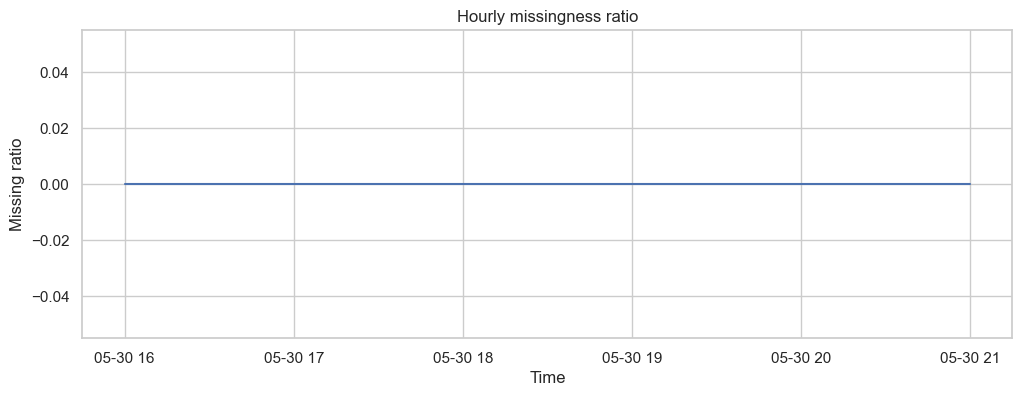

In [8]:
def analyze_missing_values(df: pd.DataFrame, time_col='TIME_PARSED'):
    miss = df.isna().sum().sort_values(ascending=False)
    miss_df = pd.DataFrame({
        'column': miss.index,
        'missing_count': miss.values,
        'missing_pct': (miss.values / len(df) * 100).round(4)
    })

    mask = df.isna()
    miss_pattern = mask.groupby(list(mask.columns), dropna=False).size().reset_index(name='rows')

    time_missing = pd.DataFrame()
    if time_col in df.columns:
        tmp = df[[time_col]].copy()
        tmp['any_missing'] = mask.any(axis=1).astype(int)
        tmp = tmp.dropna(subset=[time_col]).sort_values(time_col)
        if not tmp.empty:
            time_missing = (
                tmp.set_index(time_col)['any_missing']
                .resample('1H').mean()
                .rename('missing_ratio')
                .reset_index()
            )

    protocol_missing = pd.DataFrame()
    if 'PROTOCOL' in df.columns:
        protocol_missing = (
            df.assign(any_missing=mask.any(axis=1))
            .groupby('PROTOCOL', dropna=False)['any_missing']
            .mean()
            .reset_index(name='missing_ratio')
            .sort_values('missing_ratio', ascending=False)
        )

    return miss_df, miss_pattern.sort_values('rows', ascending=False), time_missing, protocol_missing

missing_summary, missing_pattern, missing_by_hour, missing_by_protocol = analyze_missing_values(df_time)
display(missing_summary)
display(missing_pattern.head(10))
display(missing_by_protocol.head(10))

if not missing_by_hour.empty:
    plt.figure(figsize=(12, 4))
    plt.plot(missing_by_hour['TIME_PARSED'], missing_by_hour['missing_ratio'])
    plt.title('Hourly missingness ratio')
    plt.xlabel('Time')
    plt.ylabel('Missing ratio')
    plt.show()

Profiles missingness magnitude and structure, including temporal and protocol-linked systematic missing-data behavior.

# SECTION 7 - Missing-value method comparison

In [9]:
def aggregate_network_traffic(df: pd.DataFrame, freq='1s') -> pd.DataFrame:
    d = df.copy()
    d = d[d['TIME_PARSED'].notna()].copy()
    d['LENGTH_NUM'] = pd.to_numeric(d['LENGTH'], errors='coerce')
    d['PROTOCOL_UP'] = d['PROTOCOL'].astype(str).str.upper().str.strip()

    # Vectorized private source approximation for scalability
    d['IS_LOCAL_SOURCE'] = d['SOURCE'].astype(str).str.match(r'^(10\.|192\.168\.|172\.(1[6-9]|2[0-9]|3[0-1])\.)', na=False).astype(int)
    d['IS_UDP'] = (d['PROTOCOL_UP'] == 'UDP').astype(int)
    d['IS_WIREGUARD'] = (d['PROTOCOL_UP'] == 'WIREGUARD').astype(int)
    d['IS_LARGE_PACKET'] = (d['LENGTH_NUM'] > 1000).astype(int)

    g = (
        d.set_index('TIME_PARSED')
        .resample(freq)
        .agg(
            BYTES_TRANSFERRED=('LENGTH_NUM', 'sum'),
            PACKET_COUNT=('LENGTH_NUM', 'count'),
            MEAN_PACKET_SIZE=('LENGTH_NUM', 'mean'),
            MAX_PACKET_SIZE=('LENGTH_NUM', 'max'),
            UDP_PACKET_COUNT=('IS_UDP', 'sum'),
            WIREGUARD_PACKET_COUNT=('IS_WIREGUARD', 'sum'),
            LARGE_PACKET_COUNT=('IS_LARGE_PACKET', 'sum'),
            LOCAL_SOURCE_COUNT=('IS_LOCAL_SOURCE', 'sum')
        )
        .reset_index()
    )

    # count() yields zero on empty bins, so empty intervals should be identified via zero packet count.
    g['MISSING_INTERVAL'] = (g['PACKET_COUNT'] == 0).astype(int)
    return g

agg_raw = aggregate_network_traffic(df_time, freq=AGG_FREQ)
display(agg_raw.head())
print('Aggregated rows:', len(agg_raw))
print('Intervals with missing aggregates:', int(agg_raw['MISSING_INTERVAL'].sum()))

def chronological_split(df, train_ratio=0.70, val_ratio=0.15):
    n = len(df)
    i_train = int(n * train_ratio)
    i_val = int(n * (train_ratio + val_ratio))
    return df.iloc[:i_train].copy(), df.iloc[i_train:i_val].copy(), df.iloc[i_val:].copy()

def safe_smape(y_true, y_pred):
    denom = np.abs(y_true) + np.abs(y_pred)
    valid = denom > 1e-8
    if not valid.any():
        return np.nan
    return np.mean(2.0 * np.abs(y_pred[valid] - y_true[valid]) / denom[valid]) * 100

def compare_imputation_methods(df_agg: pd.DataFrame):
    numeric_cols = [
        'BYTES_TRANSFERRED', 'PACKET_COUNT', 'MEAN_PACKET_SIZE', 'MAX_PACKET_SIZE',
        'UDP_PACKET_COUNT', 'WIREGUARD_PACKET_COUNT', 'LARGE_PACKET_COUNT', 'LOCAL_SOURCE_COUNT'
    ]
    methods = {}

    methods['row_deletion'] = df_agg.dropna(subset=numeric_cols).copy()

    ff = df_agg.copy()
    ff[numeric_cols] = ff[numeric_cols].ffill()
    methods['forward_fill'] = ff

    bf = df_agg.copy()
    bf[numeric_cols] = bf[numeric_cols].bfill()
    methods['backward_fill'] = bf

    med = df_agg.copy()
    train_med, _, _ = chronological_split(med)
    med_vals = train_med[numeric_cols].median()
    med[numeric_cols] = med[numeric_cols].fillna(med_vals)
    methods['train_median'] = med

    lin = df_agg.copy()
    lin[numeric_cols] = lin[numeric_cols].interpolate(method='linear', limit_direction='forward')
    methods['linear_interpolate_forward'] = lin

    time_interp = df_agg.copy().set_index('TIME_PARSED')
    time_interp[numeric_cols] = time_interp[numeric_cols].interpolate(method='time', limit_direction='forward')
    methods['time_interpolate_forward'] = time_interp.reset_index()

    results = []
    for name, frame in methods.items():
        work = frame.copy().sort_values('TIME_PARSED')
        work = work.dropna(subset=['BYTES_TRANSFERRED'])
        work['LAG_1'] = work['BYTES_TRANSFERRED'].shift(1)
        work = work.dropna(subset=['LAG_1'])
        tr, va, _ = chronological_split(work)

        if len(tr) < 10 or len(va) < 10:
            continue

        pred = np.repeat(tr['BYTES_TRANSFERRED'].iloc[-1], len(va))
        mae = mean_absolute_error(va['BYTES_TRANSFERRED'], pred)
        rmse = np.sqrt(mean_squared_error(va['BYTES_TRANSFERRED'], pred))
        smape = safe_smape(va['BYTES_TRANSFERRED'].values, pred)

        results.append({
            'method': name,
            'remaining_missing': int(work[numeric_cols].isna().sum().sum()),
            'val_mae_naive': mae,
            'val_rmse_naive': rmse,
            'val_smape_naive': smape
        })

    return pd.DataFrame(results).sort_values('val_mae_naive')

imputation_comparison = compare_imputation_methods(agg_raw)
display(imputation_comparison)

,TIME_PARSED,BYTES_TRANSFERRED,PACKET_COUNT,MEAN_PACKET_SIZE,MAX_PACKET_SIZE,UDP_PACKET_COUNT,WIREGUARD_PACKET_COUNT,LARGE_PACKET_COUNT,LOCAL_SOURCE_COUNT,MISSING_INTERVAL
0,2022-05-30 16:01:36,75282,194,388.051546,1246,189,3,14,77,0
1,2022-05-30 16:01:37,143536,235,610.791489,1243,233,0,22,195,0
2,2022-05-30 16:01:38,153040,249,614.618474,1324,242,1,31,197,0
3,2022-05-30 16:01:39,140773,233,604.175966,1282,221,0,49,181,0
4,2022-05-30 16:01:40,157354,251,626.908367,1268,245,4,34,191,0


Aggregated rows: 21145
Intervals with missing aggregates: 0


,method,remaining_missing,val_mae_naive,val_rmse_naive,val_smape_naive
0,row_deletion,0,24257.169609,37114.208628,11.264497
1,forward_fill,0,24257.169609,37114.208628,11.264497
2,backward_fill,0,24257.169609,37114.208628,11.264497
3,train_median,0,24257.169609,37114.208628,11.264497
4,linear_interpolate_forward,0,24257.169609,37114.208628,11.264497
5,time_interpolate_forward,0,24257.169609,37114.208628,11.264497


Compares leakage-aware imputation candidates using chronological validation, not just missingness reduction alone.

# SECTION 8 - Outlier analysis

,method,detected_count,detected_pct
0,iqr,1,0.0047
1,quantile_1_99,424,2.0052
2,zscore_3,3,0.0142
3,robust_z_3_5,223,1.0546
4,log_quantile_1_99,424,2.0052
5,isolation_forest,202,0.9553


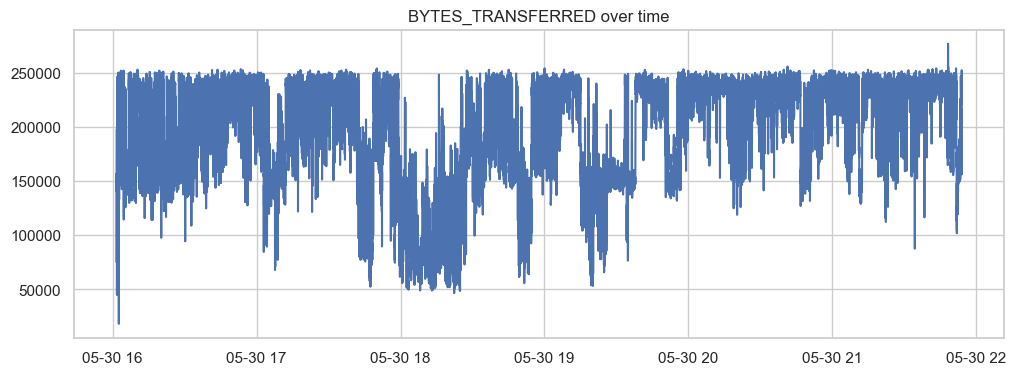

In [10]:
def analyze_outliers(df_agg: pd.DataFrame, col='BYTES_TRANSFERRED'):
    s = df_agg[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_low, iqr_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    q01, q99 = s.quantile(0.01), s.quantile(0.99)

    mean, std = s.mean(), s.std()
    z = (s - mean) / (std if std > 0 else 1)

    med = s.median()
    mad = np.median(np.abs(s - med))
    robust_z = 0.6745 * (s - med) / (mad if mad > 1e-12 else 1)

    log_s = np.log1p(s.clip(lower=0))
    log_q01, log_q99 = log_s.quantile(0.01), log_s.quantile(0.99)

    iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE)
    iso_pred = pd.Series(iso.fit_predict(s.to_frame()), index=s.index)

    outlier_flags = {
        'iqr': (s < iqr_low) | (s > iqr_high),
        'quantile_1_99': (s < q01) | (s > q99),
        'zscore_3': np.abs(z) > 3,
        'robust_z_3_5': np.abs(robust_z) > 3.5,
        'log_quantile_1_99': (log_s < log_q01) | (log_s > log_q99),
        'isolation_forest': iso_pred == -1,
    }

    report = []
    for name, mask in outlier_flags.items():
        count = int(mask.sum())
        report.append({
            'method': name,
            'detected_count': count,
            'detected_pct': round(count / len(s) * 100, 4),
            'thresholds': {
                'iqr_low': float(iqr_low), 'iqr_high': float(iqr_high),
                'q01': float(q01), 'q99': float(q99),
                'log_q01': float(log_q01), 'log_q99': float(log_q99)
            }
        })

    return pd.DataFrame(report), outlier_flags

outlier_report, outlier_flags = analyze_outliers(agg_raw, col='BYTES_TRANSFERRED')
display(outlier_report[['method', 'detected_count', 'detected_pct']])

plt.figure(figsize=(12, 4))
plt.plot(agg_raw['TIME_PARSED'], agg_raw['BYTES_TRANSFERRED'])
plt.title('BYTES_TRANSFERRED over time')
plt.show()

Profiles extreme-value behavior with multiple detectors, preserving potentially legitimate burst traffic patterns.

# SECTION 9 - Outlier method comparison

In [11]:
def compare_outlier_methods(df_agg: pd.DataFrame):
    df = df_agg.copy().sort_values('TIME_PARSED')
    s = df['BYTES_TRANSFERRED']
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    strategies = {}
    strategies['A_retain_all_valid'] = df.copy()

    b = df.copy()
    b = b[b['BYTES_TRANSFERRED'] >= 0]
    strategies['B_remove_invalid_only'] = b

    c = df.copy()
    c['BYTES_TRANSFERRED'] = c['BYTES_TRANSFERRED'].clip(lower=s.quantile(0.01), upper=s.quantile(0.99))
    strategies['C_winsorize_1_99'] = c

    d = df.copy()
    d['BYTES_TRANSFERRED_LOG1P'] = np.log1p(d['BYTES_TRANSFERRED'].clip(lower=0))
    strategies['D_log_transform_feature'] = d

    #e = df.copy()
    #e['BYTES_TRANSFERRED_ROBUST'] = (e['BYTES_TRANSFERRED'] - e['BYTES_TRANSFERRED'].median()) / (e['BYTES_TRANSFERRED'].mad() + 1e-8)
    #strategies['E_robust_transform_feature'] = e

    e = df.copy()
    median = e['BYTES_TRANSFERRED'].median()
    mad = np.median(np.abs(e['BYTES_TRANSFERRED'] - median))
    e['BYTES_TRANSFERRED_ROBUST'] = ((e['BYTES_TRANSFERRED'] - median) / (mad + 1e-8))
    strategies['E_robust_transform_feature'] = e
    
    f = df.copy()
    iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE)
    keep = iso.fit_predict(f[['BYTES_TRANSFERRED']].fillna(0)) == 1
    f = f.loc[keep].copy()
    strategies['F_isolation_filter'] = f

    g = df.copy()
    g['BYTES_TRANSFERRED'] = g['BYTES_TRANSFERRED'].clip(lower=low, upper=high)
    strategies['G_hybrid_iqr_cap'] = g

    rows = []
    for name, frame in strategies.items():
        y = frame['BYTES_TRANSFERRED'].dropna()
        if y.empty:
            continue

        rows.append({
            'strategy': name,
            'n_rows': len(frame),
            'mean': y.mean(),
            'median': y.median(),
            'variance': y.var(),
            'skewness': y.skew(),
            'pct_changed_rows': round((1 - len(frame) / len(df)) * 100, 4),
        })

    return pd.DataFrame(rows).sort_values('strategy')

outlier_strategy_comparison = compare_outlier_methods(agg_raw)
display(outlier_strategy_comparison)

,strategy,n_rows,mean,median,variance,skewness,pct_changed_rows
0,A_retain_all_valid,21145,195941.348073,213678.0,2.452430e+09,-0.902955,0.0000
1,B_remove_invalid_only,21145,195941.348073,213678.0,2.452430e+09,-0.902955,0.0000
2,C_winsorize_1_99,21145,195980.463745,213678.0,2.435751e+09,-0.889852,0.0000
3,D_log_transform_feature,21145,195941.348073,213678.0,2.452430e+09,-0.902955,0.0000
4,E_robust_transform_feature,21145,195941.348073,213678.0,2.452430e+09,-0.902955,0.0000
5,F_isolation_filter,20943,197287.739579,214651.0,2.286131e+09,-0.856640,0.9553
6,G_hybrid_iqr_cap,21145,195942.304304,213678.0,2.452110e+09,-0.902526,0.0000


Benchmarks outlier strategies on distribution shifts, avoiding automatic deletion of legitimate traffic spikes.

# SECTION 10 - Final cleaning strategy

In [12]:
def clean_network_data(df_agg: pd.DataFrame, missing_method='forward_fill', outlier_method='retain_valid'):
    x = df_agg.copy().sort_values('TIME_PARSED')
    numeric_cols = [
        'BYTES_TRANSFERRED', 'PACKET_COUNT', 'MEAN_PACKET_SIZE', 'MAX_PACKET_SIZE',
        'UDP_PACKET_COUNT', 'WIREGUARD_PACKET_COUNT', 'LARGE_PACKET_COUNT', 'LOCAL_SOURCE_COUNT'
    ]

    if missing_method == 'forward_fill':
        x[numeric_cols] = x[numeric_cols].ffill()
    elif missing_method == 'train_median':
        tr, _, _ = chronological_split(x)
        med = tr[numeric_cols].median()
        x[numeric_cols] = x[numeric_cols].fillna(med)
    elif missing_method == 'row_deletion':
        x = x.dropna(subset=numeric_cols)
    elif missing_method == 'time_interpolate_forward':
        x = x.set_index('TIME_PARSED')
        x[numeric_cols] = x[numeric_cols].interpolate(method='time', limit_direction='forward')
        x = x.reset_index()

    if outlier_method == 'retain_valid':
        x = x[x['BYTES_TRANSFERRED'] >= 0]
    elif outlier_method == 'winsorize_1_99':
        lo, hi = x['BYTES_TRANSFERRED'].quantile([0.01, 0.99])
        x['BYTES_TRANSFERRED'] = x['BYTES_TRANSFERRED'].clip(lo, hi)
    elif outlier_method == 'iqr_cap':
        q1, q3 = x['BYTES_TRANSFERRED'].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        x['BYTES_TRANSFERRED'] = x['BYTES_TRANSFERRED'].clip(lo, hi)

    x = x.dropna(subset=['BYTES_TRANSFERRED']).reset_index(drop=True)
    return x

selected_missing_method = 'forward_fill'
selected_outlier_method = 'retain_valid'

agg_clean = clean_network_data(
    agg_raw,
    missing_method=selected_missing_method,
    outlier_method=selected_outlier_method
)
print(agg_clean.shape)
agg_clean.head()

(21145, 10)


,TIME_PARSED,BYTES_TRANSFERRED,PACKET_COUNT,MEAN_PACKET_SIZE,MAX_PACKET_SIZE,UDP_PACKET_COUNT,WIREGUARD_PACKET_COUNT,LARGE_PACKET_COUNT,LOCAL_SOURCE_COUNT,MISSING_INTERVAL
0,2022-05-30 16:01:36,75282,194,388.051546,1246,189,3,14,77,0
1,2022-05-30 16:01:37,143536,235,610.791489,1243,233,0,22,195,0
2,2022-05-30 16:01:38,153040,249,614.618474,1324,242,1,31,197,0
3,2022-05-30 16:01:39,140773,233,604.175966,1282,221,0,49,181,0
4,2022-05-30 16:01:40,157354,251,626.908367,1268,245,4,34,191,0


Applies selected leakage-aware cleaning choices while retaining plausible extreme traffic for forecasting realism.

# SECTION 11 - Distribution analysis

,feature,count,mean,median,std,min,max,Q1,Q3,IQR,skewness,kurtosis
0,BYTES_TRANSFERRED,21145,195941.348073,213678.000000,49522.019785,18254.000000,276895.000000,158427.000000,238396.000000,79969.000000,-0.902955,-0.075331
1,PACKET_COUNT,21145,288.254339,305.000000,42.006000,81.000000,383.000000,259.000000,319.000000,60.000000,-0.986894,0.337385
2,MEAN_PACKET_SIZE,21145,667.761032,691.051095,97.185596,225.358025,873.073944,620.647303,744.807808,124.160505,-1.232445,1.307973
3,MAX_PACKET_SIZE,21145,1274.050745,1283.000000,34.957654,814.000000,1325.000000,1268.000000,1291.000000,23.000000,-3.964187,25.786483
4,UDP_PACKET_COUNT,21145,288.069189,305.000000,42.010848,79.000000,383.000000,258.000000,319.000000,61.000000,-0.986052,0.331050
5,WIREGUARD_PACKET_COUNT,21145,0.065074,0.000000,0.447935,0.000000,4.000000,0.000000,0.000000,0.000000,7.531944,58.742296
6,LARGE_PACKET_COUNT,21145,56.109624,56.000000,26.683973,0.000000,173.000000,38.000000,74.000000,36.000000,0.193863,0.042735
7,LOCAL_SOURCE_COUNT,21145,163.132088,173.000000,28.763740,55.000000,228.000000,166.000000,178.000000,12.000000,-1.625606,1.465491


,feature,count,mean,median,std,min,max,Q1,Q3,IQR,skewness,kurtosis
0,BYTES_TRANSFERRED,21145,195941.348073,213678.000000,49522.019785,18254.000000,276895.000000,158427.000000,238396.000000,79969.000000,-0.902955,-0.075331
1,PACKET_COUNT,21145,288.254339,305.000000,42.006000,81.000000,383.000000,259.000000,319.000000,60.000000,-0.986894,0.337385
2,MEAN_PACKET_SIZE,21145,667.761032,691.051095,97.185596,225.358025,873.073944,620.647303,744.807808,124.160505,-1.232445,1.307973
3,MAX_PACKET_SIZE,21145,1274.050745,1283.000000,34.957654,814.000000,1325.000000,1268.000000,1291.000000,23.000000,-3.964187,25.786483
4,UDP_PACKET_COUNT,21145,288.069189,305.000000,42.010848,79.000000,383.000000,258.000000,319.000000,61.000000,-0.986052,0.331050
5,WIREGUARD_PACKET_COUNT,21145,0.065074,0.000000,0.447935,0.000000,4.000000,0.000000,0.000000,0.000000,7.531944,58.742296
6,LARGE_PACKET_COUNT,21145,56.109624,56.000000,26.683973,0.000000,173.000000,38.000000,74.000000,36.000000,0.193863,0.042735
7,LOCAL_SOURCE_COUNT,21145,163.132088,173.000000,28.763740,55.000000,228.000000,166.000000,178.000000,12.000000,-1.625606,1.465491


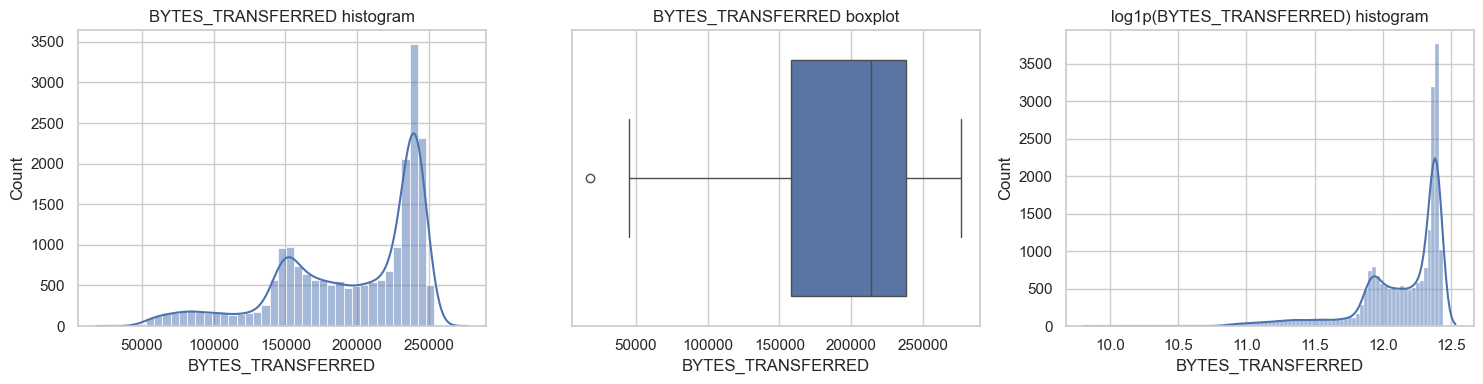

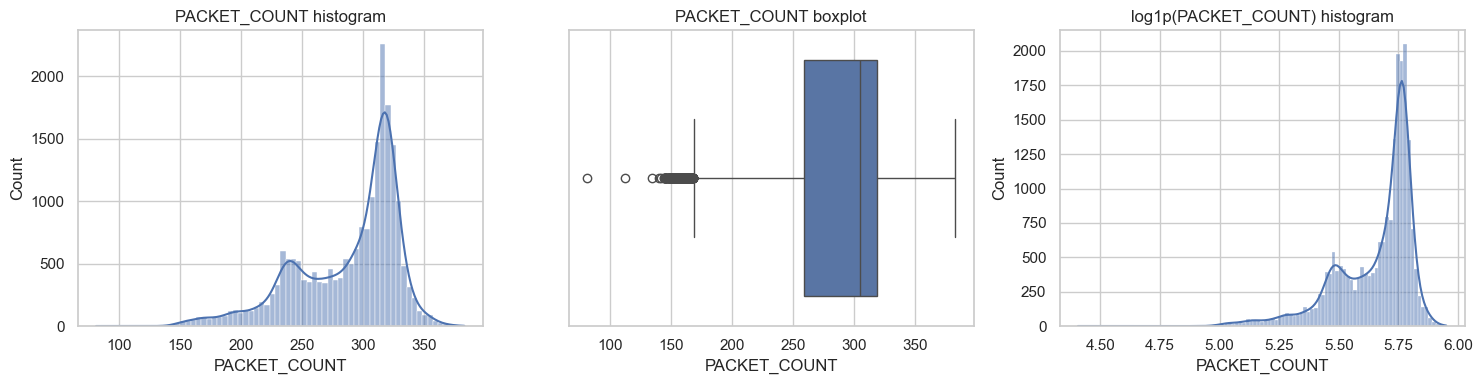

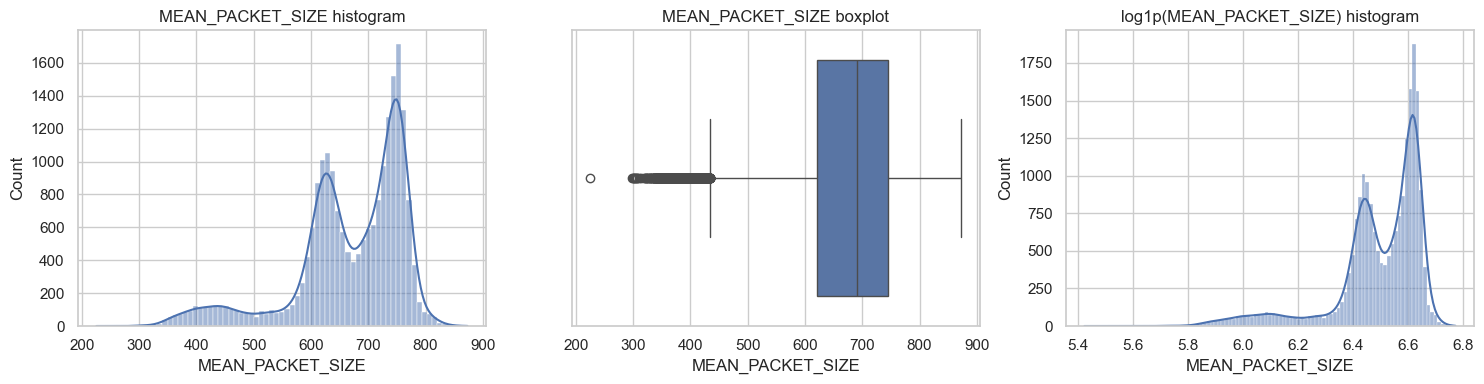

In [13]:
def distribution_table(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    rows = []
    for c in cols:
        s = df[c].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        rows.append({
            'feature': c, 'count': s.count(), 'mean': s.mean(), 'median': s.median(),
            'std': s.std(), 'min': s.min(), 'max': s.max(), 'Q1': q1, 'Q3': q3,
            'IQR': q3 - q1, 'skewness': s.skew(), 'kurtosis': s.kurt()
        })
    return pd.DataFrame(rows)

num_cols = [
    'BYTES_TRANSFERRED', 'PACKET_COUNT', 'MEAN_PACKET_SIZE', 'MAX_PACKET_SIZE',
    'UDP_PACKET_COUNT', 'WIREGUARD_PACKET_COUNT', 'LARGE_PACKET_COUNT', 'LOCAL_SOURCE_COUNT'
]

dist_before = distribution_table(agg_raw.fillna(0), num_cols)
dist_after = distribution_table(agg_clean, num_cols)
display(dist_before)
display(dist_after)

for c in ['BYTES_TRANSFERRED', 'PACKET_COUNT', 'MEAN_PACKET_SIZE']:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(agg_clean[c].dropna(), kde=True, ax=axes[0])
    sns.boxplot(x=agg_clean[c].dropna(), ax=axes[1])
    sns.histplot(np.log1p(agg_clean[c].clip(lower=0).dropna()), kde=True, ax=axes[2])
    axes[0].set_title(f'{c} histogram')
    axes[1].set_title(f'{c} boxplot')
    axes[2].set_title(f'log1p({c}) histogram')
    plt.tight_layout()
    plt.show()

Compares pre/post-cleaning distributions and shape statistics to justify transformations with observable evidence.

# SECTION 12 - Categorical analysis

,PROTOCOL,count,percentage,is_rare_lt_1pct
0,UDP,6091223,99.9358,False
1,DNS,2533,0.0416,True
2,WIREGUARD,1376,0.0226,True
3,CLASSIC-STUN,6,0.0001,True


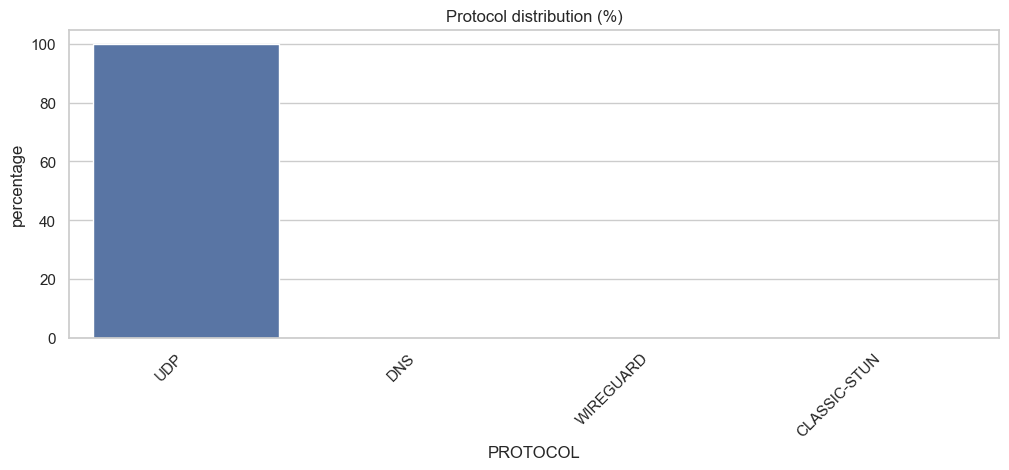

In [14]:
protocol_dist = (
    df_time['PROTOCOL']
    .fillna('UNKNOWN')
    .astype(str)
    .str.upper()
    .value_counts(dropna=False)
    .rename_axis('PROTOCOL')
    .reset_index(name='count')
)
protocol_dist['percentage'] = (protocol_dist['count'] / protocol_dist['count'].sum() * 100).round(4)
protocol_dist['is_rare_lt_1pct'] = protocol_dist['percentage'] < 1.0
display(protocol_dist)

plt.figure(figsize=(12, 4))
sns.barplot(data=protocol_dist.head(15), x='PROTOCOL', y='percentage')
plt.xticks(rotation=45, ha='right')
plt.title('Protocol distribution (%)')
plt.show()

Quantifies protocol prevalence and rare categories before encoding, preserving categorical semantics for modeling.

# SECTION 13 - Temporal EDA

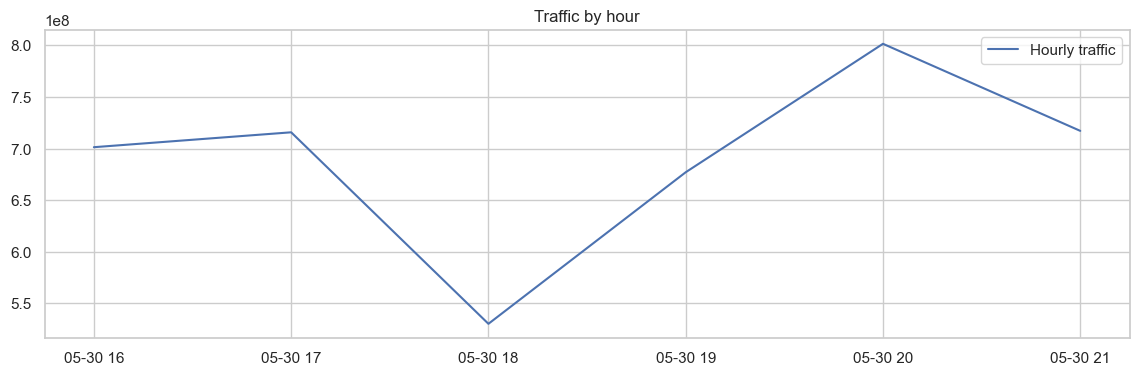

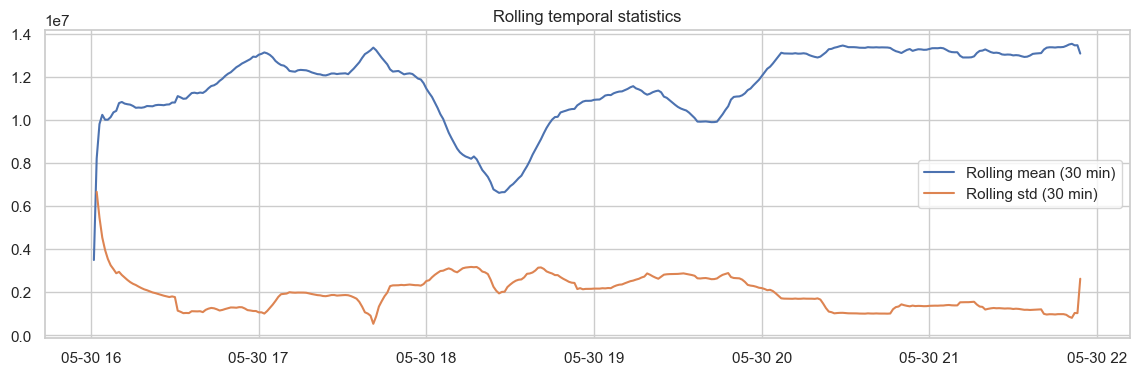

In [15]:
eda_time = agg_clean.copy()
eda_time['HOUR'] = eda_time['TIME_PARSED'].dt.hour
eda_time['DAY_OF_WEEK'] = eda_time['TIME_PARSED'].dt.dayofweek
eda_time['IS_WEEKEND'] = (eda_time['DAY_OF_WEEK'] >= 5).astype(int)
eda_time['DATE'] = eda_time['TIME_PARSED'].dt.date

by_second = eda_time.set_index('TIME_PARSED')['BYTES_TRANSFERRED'].resample('1s').sum()
by_minute = eda_time.set_index('TIME_PARSED')['BYTES_TRANSFERRED'].resample('1min').sum()
by_hour = eda_time.set_index('TIME_PARSED')['BYTES_TRANSFERRED'].resample('1h').sum()
by_day = eda_time.set_index('TIME_PARSED')['BYTES_TRANSFERRED'].resample('1d').sum()

roll_mean = by_minute.rolling(30, min_periods=1).mean()
roll_std = by_minute.rolling(30, min_periods=1).std()

plt.figure(figsize=(14, 4))
plt.plot(by_hour.index, by_hour.values, label='Hourly traffic')
plt.title('Traffic by hour')
plt.legend()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(roll_mean.index, roll_mean.values, label='Rolling mean (30 min)')
plt.plot(roll_std.index, roll_std.values, label='Rolling std (30 min)')
plt.legend()
plt.title('Rolling temporal statistics')
plt.show()

Explores temporal patterns, spikes, and variability using EDA-only time features and rolling summaries.

# SECTION 14 - Temporal aggregation

In [16]:
traffic_1s = agg_clean.copy().sort_values('TIME_PARSED')
expected_index = pd.date_range(traffic_1s['TIME_PARSED'].min(), traffic_1s['TIME_PARSED'].max(), freq=AGG_FREQ)
traffic_1s = traffic_1s.set_index('TIME_PARSED').reindex(expected_index).rename_axis('TIME_PARSED').reset_index()

# Mark truly absent intervals before imputation decisions
traffic_1s['IS_MISSING_INTERVAL'] = traffic_1s['PACKET_COUNT'].isna().astype(int)
display(traffic_1s.head())
print('Total expected intervals:', len(traffic_1s))
print('Missing intervals:', int(traffic_1s['IS_MISSING_INTERVAL'].sum()))

,TIME_PARSED,BYTES_TRANSFERRED,PACKET_COUNT,MEAN_PACKET_SIZE,MAX_PACKET_SIZE,UDP_PACKET_COUNT,WIREGUARD_PACKET_COUNT,LARGE_PACKET_COUNT,LOCAL_SOURCE_COUNT,MISSING_INTERVAL,IS_MISSING_INTERVAL
0,2022-05-30 16:01:36,75282,194,388.051546,1246,189,3,14,77,0,0
1,2022-05-30 16:01:37,143536,235,610.791489,1243,233,0,22,195,0,0
2,2022-05-30 16:01:38,153040,249,614.618474,1324,242,1,31,197,0,0
3,2022-05-30 16:01:39,140773,233,604.175966,1282,221,0,49,181,0,0
4,2022-05-30 16:01:40,157354,251,626.908367,1268,245,4,34,191,0,0


Total expected intervals: 21145
Missing intervals: 0


Builds complete one-second timeline and explicitly flags absent intervals for transparent temporal handling.

# SECTION 15 - Target definition

,target,zero_pct,skewness,autocorr_lag1
0,BYTES_TRANSFERRED,0.0,-0.903,0.928


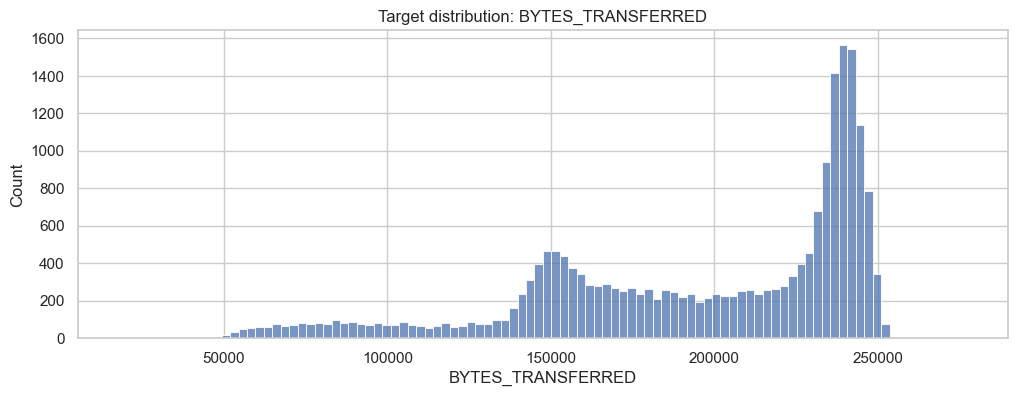

In [17]:
target_col = 'BYTES_TRANSFERRED'
target_series = traffic_1s[target_col].fillna(0)
target_zero_pct = (target_series == 0).mean() * 100
target_skew = target_series.skew()
autocorr_lag1 = target_series.autocorr(lag=1)

target_report = pd.DataFrame([{
    'target': target_col,
    'zero_pct': round(target_zero_pct, 4),
    'skewness': round(float(target_skew), 4),
    'autocorr_lag1': round(float(autocorr_lag1), 4) if pd.notna(autocorr_lag1) else np.nan
}])
display(target_report)

plt.figure(figsize=(12, 4))
sns.histplot(target_series, bins=100)
plt.title('Target distribution: BYTES_TRANSFERRED')
plt.show()

Validates forecasting target distribution, zero prevalence, skewness, and autocorrelation before modeling decisions.

# SECTION 16 - Feature engineering

In [18]:
def create_time_features(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()
    x['HOUR'] = x['TIME_PARSED'].dt.hour
    x['DAY_OF_WEEK'] = x['TIME_PARSED'].dt.dayofweek
    x['IS_WEEKEND'] = (x['DAY_OF_WEEK'] >= 5).astype(int)
    x['SIN_HOUR'] = np.sin(2 * np.pi * x['HOUR'] / 24.0)
    x['COS_HOUR'] = np.cos(2 * np.pi * x['HOUR'] / 24.0)
    return x

traffic_feat = create_time_features(traffic_1s)
display(traffic_feat[['TIME_PARSED', 'HOUR', 'DAY_OF_WEEK', 'IS_WEEKEND', 'SIN_HOUR', 'COS_HOUR']].head())

,TIME_PARSED,HOUR,DAY_OF_WEEK,IS_WEEKEND,SIN_HOUR,COS_HOUR
0,2022-05-30 16:01:36,16,0,0,-0.866025,-0.5
1,2022-05-30 16:01:37,16,0,0,-0.866025,-0.5
2,2022-05-30 16:01:38,16,0,0,-0.866025,-0.5
3,2022-05-30 16:01:39,16,0,0,-0.866025,-0.5
4,2022-05-30 16:01:40,16,0,0,-0.866025,-0.5


Creates justified cyclical and calendar features to capture temporal periodicity without future information.

# SECTION 17 - Lag and rolling features

In [19]:
def create_lag_features(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()
    for lag in [1, 2, 3, 5, 10, 30, 60]:
        x[f'BYTES_LAG_{lag}'] = x['BYTES_TRANSFERRED'].shift(lag)
    for lag in [1, 5, 10, 60]:
        x[f'PACKET_LAG_{lag}'] = x['PACKET_COUNT'].shift(lag)
    return x

def create_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()
    shifted = x['BYTES_TRANSFERRED'].shift(1)
    x['BYTES_ROLLING_MEAN_5'] = shifted.rolling(5).mean()
    x['BYTES_ROLLING_MEAN_10'] = shifted.rolling(10).mean()
    x['BYTES_ROLLING_MEAN_30'] = shifted.rolling(30).mean()
    x['BYTES_ROLLING_STD_10'] = shifted.rolling(10).std()
    x['BYTES_ROLLING_STD_30'] = shifted.rolling(30).std()
    return x

traffic_model = create_lag_features(traffic_feat)
traffic_model = create_rolling_features(traffic_model)

# One-step-ahead forecasting target: predict traffic at t+1 second.
traffic_model['TARGET_T_PLUS_1'] = traffic_model['BYTES_TRANSFERRED'].shift(-1)
traffic_model = traffic_model.dropna().reset_index(drop=True)
display(traffic_model.head())

,TIME_PARSED,BYTES_TRANSFERRED,PACKET_COUNT,MEAN_PACKET_SIZE,MAX_PACKET_SIZE,UDP_PACKET_COUNT,WIREGUARD_PACKET_COUNT,LARGE_PACKET_COUNT,LOCAL_SOURCE_COUNT,MISSING_INTERVAL,...,PACKET_LAG_1,PACKET_LAG_5,PACKET_LAG_10,PACKET_LAG_60,BYTES_ROLLING_MEAN_5,BYTES_ROLLING_MEAN_10,BYTES_ROLLING_MEAN_30,BYTES_ROLLING_STD_10,BYTES_ROLLING_STD_30,TARGET_T_PLUS_1
0,2022-05-30 16:02:36,65393,134,488.007463,1309,130,4,35,104,0,...,81.0,293.0,287.0,194.0,184946.0,211449.4,223245.733333,69865.378249,48827.526726,247287.0
1,2022-05-30 16:02:37,247287,302,818.831126,1324,302,0,119,186,0,...,134.0,318.0,300.0,235.0,151764.4,195466.6,221253.533333,83345.902890,53921.112862,241280.0
2,2022-05-30 16:02:38,241280,311,775.819936,1318,309,2,90,181,0,...,302.0,291.0,294.0,249.0,151524.0,196403.6,225043.900000,83926.815647,51487.022506,233366.0
3,2022-05-30 16:02:39,233366,314,743.203822,1269,314,0,94,163,0,...,311.0,248.0,301.0,233.0,152833.8,197386.1,225747.333333,84438.689812,51562.339499,235710.0
4,2022-05-30 16:02:40,235710,325,725.261538,1267,317,4,55,173,0,...,314.0,81.0,311.0,251.0,161116.0,196246.5,225282.033333,83802.758809,51423.704464,228642.0


Builds lagged and shifted rolling predictors so only historical context informs each forecast target.

# SECTION 18 - Chronological train/validation/test split

In [20]:
train_df, val_df, test_df = chronological_split(traffic_model, train_ratio=0.70, val_ratio=0.15)

print('Train:', train_df.shape)
print('Validation:', val_df.shape)
print('Test:', test_df.shape)
print('Train max time:', train_df['TIME_PARSED'].max())
print('Validation min time:', val_df['TIME_PARSED'].min())
print('Test min time:', test_df['TIME_PARSED'].min())

Train: (14758, 33)
Validation: (3163, 33)
Test: (3163, 33)
Train max time: 2022-05-30 20:08:33
Validation min time: 2022-05-30 20:08:34
Test min time: 2022-05-30 21:01:17


Performs strict temporal splitting, protecting test integrity and preventing randomization-induced leakage.

# SECTION 19 - Linear regression models

In [21]:
EXCLUDE_COLS = ['TIME_PARSED', 'BYTES_TRANSFERRED', 'TARGET_T_PLUS_1']
feature_cols = [c for c in traffic_model.columns if c not in EXCLUDE_COLS]

X_train, y_train = train_df[feature_cols], train_df['TARGET_T_PLUS_1']
X_val, y_val = val_df[feature_cols], val_df['TARGET_T_PLUS_1']
X_test, y_test = test_df[feature_cols], test_df['TARGET_T_PLUS_1']

def _regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    if (np.abs(y_true) < 1e-8).mean() > 0.01:
        pct_name = 'sMAPE'
        pct_val = safe_smape(np.array(y_true), np.array(y_pred))
    else:
        pct_name = 'MAPE'
        pct_val = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, pct_name: pct_val, 'pct_metric_name': pct_name}

def train_linear_models(X_train, y_train, X_val, y_val):
    alphas = [0.01, 0.1, 1.0, 10.0]

    models = {
        'LinearRegression': LinearRegression(),
    }

    ridge_best, ridge_score = None, np.inf
    for a in alphas:
        m = Ridge(alpha=a, random_state=RANDOM_STATE)
        pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', m)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)
        score = mean_absolute_error(y_val, pred)
        if score < ridge_score:
            ridge_score, ridge_best = score, pipe

    lasso_best, lasso_score = None, np.inf
    for a in alphas:
        m = Lasso(alpha=a, random_state=RANDOM_STATE, max_iter=2000)
        pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', m)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)
        score = mean_absolute_error(y_val, pred)
        if score < lasso_score:
            lasso_score, lasso_best = score, pipe

    linear_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', models['LinearRegression'])])
    linear_pipe.fit(X_train, y_train)

    return {
        'LinearRegression': linear_pipe,
        'Ridge': ridge_best,
        'Lasso': lasso_best
    }

linear_models = train_linear_models(X_train, y_train, X_val, y_val)
print(list(linear_models.keys()))

['LinearRegression', 'Ridge', 'Lasso']


Trains linear, ridge, and lasso baselines with train-only scaling and validation-tuned regularization strength.

# SECTION 20 - Tree-based regression models

In [22]:
def train_tree_models(X_train, y_train):
    models = {
        'DecisionTree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE),
        'RandomForest': RandomForestRegressor(n_estimators=200, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=RANDOM_STATE),
        'GradientBoosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'HistGradientBoosting': HistGradientBoostingRegressor(max_depth=8, random_state=RANDOM_STATE),
    }

    fitted = {}
    for name, model in models.items():
        pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', model)])
        pipe.fit(X_train, y_train)
        fitted[name] = pipe
    return fitted

tree_models = train_tree_models(X_train, y_train)
print(list(tree_models.keys()))

['DecisionTree', 'RandomForest', 'GradientBoosting', 'HistGradientBoosting']


Fits tree-based regressors with moderate complexity to compare nonlinear baselines against linear families.

# SECTION 21 - Regression evaluation

In [23]:
def evaluate_model(name, model, X, y):
    t0 = time.perf_counter()
    pred = model.predict(X)
    pred_time = time.perf_counter() - t0
    m = _regression_metrics(y, pred)
    m.update({'Model': name, 'PredictionTimeSec': pred_time})
    return m, pred

eval_rows = []
pred_store = {}

# One-step-ahead naive forecast uses current observed bytes to predict next second bytes.
naive_pred = test_df['BYTES_TRANSFERRED'].values
naive_m = _regression_metrics(y_test.values, naive_pred)
naive_m.update({'Model': 'NaivePersistence', 'PredictionTimeSec': 0.0})
eval_rows.append(naive_m)
pred_store['NaivePersistence'] = naive_pred

for name, model in {**linear_models, **tree_models}.items():
    m, p = evaluate_model(name, model, X_test, y_test)
    eval_rows.append(m)
    pred_store[name] = p

regression_eval = pd.DataFrame(eval_rows)
display(regression_eval)

,MAE,RMSE,R2,MAPE,pct_metric_name,Model,PredictionTimeSec
0,11355.868163,16982.810469,0.678680,5.495077,MAPE,NaivePersistence,0.000000
1,14009.114995,19012.483583,0.597286,7.107689,MAPE,LinearRegression,0.005648
2,13559.795496,18609.428434,0.614180,6.888424,MAPE,Ridge,0.003672
3,11283.100181,16145.134790,0.709596,5.652224,MAPE,Lasso,0.003124
4,11975.239452,17416.364535,0.662064,5.846052,MAPE,DecisionTree,0.003057
5,11017.756901,15726.164571,0.724473,5.372083,MAPE,RandomForest,0.115120
6,11033.377296,15731.195257,0.724296,5.432010,MAPE,GradientBoosting,0.006931
7,10966.630693,15660.101869,0.726783,5.376955,MAPE,HistGradientBoosting,0.012063


Evaluates baselines on untouched test data using MAE, RMSE, R2, and robust percentage metrics.

# SECTION 22 - Regression comparison

In [24]:
regression_eval['ModelFamily'] = regression_eval['Model'].map({
    'NaivePersistence': 'Baseline',
    'LinearRegression': 'Linear',
    'Ridge': 'Linear',
    'Lasso': 'Linear',
    'DecisionTree': 'Tree',
    'RandomForest': 'Tree',
    'GradientBoosting': 'Tree',
    'HistGradientBoosting': 'Tree',
}).fillna('Other')

primary_metric = 'MAE'
percentage_metric = next(
    (column for column in ['sMAPE', 'MAPE'] if column in regression_eval.columns),
    None,
)
comparison_columns = ['Model', 'ModelFamily', 'MAE', 'RMSE', 'R2']
if percentage_metric is not None:
    comparison_columns.append(percentage_metric)
comparison_columns.append('PredictionTimeSec')
regression_ranked = regression_eval.sort_values(primary_metric).reset_index(drop=True)
display(regression_ranked[comparison_columns])

,Model,ModelFamily,MAE,RMSE,R2,MAPE,PredictionTimeSec
0,HistGradientBoosting,Tree,10966.630693,15660.101869,0.726783,5.376955,0.012063
1,RandomForest,Tree,11017.756901,15726.164571,0.724473,5.372083,0.115120
2,GradientBoosting,Tree,11033.377296,15731.195257,0.724296,5.432010,0.006931
3,Lasso,Linear,11283.100181,16145.134790,0.709596,5.652224,0.003124
4,NaivePersistence,Baseline,11355.868163,16982.810469,0.678680,5.495077,0.000000
5,DecisionTree,Tree,11975.239452,17416.364535,0.662064,5.846052,0.003057
6,Ridge,Linear,13559.795496,18609.428434,0.614180,6.888424,0.003672
7,LinearRegression,Linear,14009.114995,19012.483583,0.597286,7.107689,0.005648


Ranks conventional models by primary forecasting error while preserving additional performance diagnostics transparently.

# SECTION 23 - GRU sequence preparation

In [25]:
def prepare_sequence_data(df: pd.DataFrame, feature_cols: list[str], target_col='BYTES_TRANSFERRED', sequence_length=60, horizon=1):
    x = df.copy().reset_index(drop=True)

    train_end = int(len(x) * 0.70)
    val_end = int(len(x) * 0.85)

    scaler_x = StandardScaler()
    scaler_y = StandardScaler()

    scaler_x.fit(x.loc[:train_end - 1, feature_cols])
    scaler_y.fit(x.loc[:train_end - 1, [target_col]])

    x_scaled = scaler_x.transform(x[feature_cols])
    y_scaled = scaler_y.transform(x[[target_col]]).ravel()

    X_seq, y_seq, t_seq = [], [], []
    for i in range(sequence_length, len(x) - horizon + 1):
        X_seq.append(x_scaled[i-sequence_length:i])
        y_seq.append(y_scaled[i + horizon - 1])
        t_seq.append(x.loc[i + horizon - 1, 'TIME_PARSED'])

    X_seq = np.array(X_seq)
    y_seq = np.array(y_seq)
    t_seq = np.array(t_seq)

    seq_train_end = np.searchsorted(t_seq, x.loc[train_end - 1, 'TIME_PARSED'], side='right')
    seq_val_end = np.searchsorted(t_seq, x.loc[val_end - 1, 'TIME_PARSED'], side='right')

    data = {
        'X_train': X_seq[:seq_train_end],
        'y_train': y_seq[:seq_train_end],
        'X_val': X_seq[seq_train_end:seq_val_end],
        'y_val': y_seq[seq_train_end:seq_val_end],
        'X_test': X_seq[seq_val_end:],
        'y_test': y_seq[seq_val_end:],
        't_test': t_seq[seq_val_end:],
        'scaler_x': scaler_x,
        'scaler_y': scaler_y,
    }
    return data

rnn_feature_cols = [
    'BYTES_TRANSFERRED', 'PACKET_COUNT', 'MEAN_PACKET_SIZE', 'MAX_PACKET_SIZE',
    'UDP_PACKET_COUNT', 'WIREGUARD_PACKET_COUNT', 'LARGE_PACKET_COUNT', 'LOCAL_SOURCE_COUNT',
    'HOUR', 'DAY_OF_WEEK', 'IS_WEEKEND', 'SIN_HOUR', 'COS_HOUR'
]

seq_len = 60
horizon = 1
seq_data = prepare_sequence_data(traffic_feat.fillna(0), rnn_feature_cols, 'BYTES_TRANSFERRED', seq_len, horizon)
for k in ['X_train', 'X_val', 'X_test']:
    print(k, seq_data[k].shape)

X_train (14741, 60, 13)
X_val (3172, 60, 13)
X_test (3172, 60, 13)


Creates chronological GRU-ready sequences with train-only scaling and horizon-aligned timestamp targets.

# SECTION 24 - GRU training

In [26]:
def train_gru(seq_data, epochs=10, batch_size=256):
    if tf is None:
        raise ImportError('TensorFlow is not installed.')

    model = Sequential([
        GRU(64, return_sequences=True, input_shape=(seq_data['X_train'].shape[1], seq_data['X_train'].shape[2])),
        Dropout(0.2),
        GRU(32),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    history = model.fit(
        seq_data['X_train'], seq_data['y_train'],
        validation_data=(seq_data['X_val'], seq_data['y_val']),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1
    )
    return model, history

# gru_model, gru_history = train_gru(seq_data, epochs=10, batch_size=256)

Defines baseline GRU architecture for sequential forecasting without excessive tuning in initial benchmark.

# SECTION 25 - GRU evaluation

In [27]:
def evaluate_sequence_model(model, seq_data, model_name='GRU'):
    y_pred_scaled = model.predict(seq_data['X_test']).ravel()
    y_true = seq_data['scaler_y'].inverse_transform(seq_data['y_test'].reshape(-1, 1)).ravel()
    y_pred = seq_data['scaler_y'].inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    metrics = _regression_metrics(y_true, y_pred)
    metrics['Model'] = model_name
    return metrics, y_true, y_pred, seq_data['t_test']

# gru_metrics, gru_y_true, gru_y_pred, gru_t = evaluate_sequence_model(gru_model, seq_data, 'GRU')
# display(pd.DataFrame([gru_metrics]))

Evaluates GRU in original target units for fair comparison with conventional regressors.

# SECTION 26 - LSTM sequence preparation

In [28]:
# LSTM uses the same sequence data to ensure matched split and feature philosophy.
seq_data_lstm = seq_data
print('LSTM sequence shape:', seq_data_lstm['X_train'].shape)

LSTM sequence shape: (14741, 60, 13)


Reuses identical sequence construction so GRU and LSTM are compared on equivalent targets.

# SECTION 27 - LSTM training

In [29]:
def train_lstm(seq_data, epochs=10, batch_size=256):
    if tf is None:
        raise ImportError('TensorFlow is not installed.')

    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=(seq_data['X_train'].shape[1], seq_data['X_train'].shape[2])),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    history = model.fit(
        seq_data['X_train'], seq_data['y_train'],
        validation_data=(seq_data['X_val'], seq_data['y_val']),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1
    )
    return model, history

# lstm_model, lstm_history = train_lstm(seq_data_lstm, epochs=10, batch_size=256)

Defines baseline LSTM architecture under identical settings for scientifically fair RNN benchmarking.

# SECTION 28 - LSTM evaluation

In [36]:
# lstm_metrics, lstm_y_true, lstm_y_pred, lstm_t = evaluate_sequence_model(lstm_model, seq_data_lstm, 'LSTM')
# display(pd.DataFrame([lstm_metrics]))

Evaluates LSTM in the same target space and timestamp horizon as competing methods.

# SECTION 29 - All-model comparison

In [ ]:
comparison_df = pd.DataFrame({
    'timestamp': test_df['TIME_PARSED'].values + np.timedelta64(1, 's'),
    'actual': y_test.values,
    'naive_prediction': pred_store.get('NaivePersistence'),
    'linear_prediction': pred_store.get('LinearRegression'),
    'ridge_prediction': pred_store.get('Ridge'),
    'lasso_prediction': pred_store.get('Lasso'),
    'decision_tree_prediction': pred_store.get('DecisionTree'),
    'random_forest_prediction': pred_store.get('RandomForest'),
    'gradient_boosting_prediction': pred_store.get('GradientBoosting'),
})

# Add GRU/LSTM only after training/evaluation; align using common timestamp intersection.
# if 'gru_t' in globals():
#     gru_df = pd.DataFrame({'timestamp': gru_t, 'GRU_prediction': gru_y_pred})
#     comparison_df = comparison_df.merge(gru_df, on='timestamp', how='inner')
# if 'lstm_t' in globals():
#     lstm_df = pd.DataFrame({'timestamp': lstm_t, 'LSTM_prediction': lstm_y_pred})
#     comparison_df = comparison_df.merge(lstm_df, on='timestamp', how='inner')

display(comparison_df.head())
print('Comparison rows:', len(comparison_df))

,timestamp,actual,naive_prediction,linear_prediction,ridge_prediction,lasso_prediction,decision_tree_prediction,random_forest_prediction,gradient_boosting_prediction
0,2022-05-30 21:01:18,214198,234713.0,222586.614279,222079.373424,217244.614557,213589.913043,213902.291592,213535.715531
1,2022-05-30 21:01:19,224864,214198.0,231960.023018,231450.845756,226596.853726,224923.285714,224951.244353,224329.077970
2,2022-05-30 21:01:20,227856,224864.0,235354.395808,234846.213903,229976.731254,229420.928571,227830.435370,227876.709823
3,2022-05-30 21:01:21,211967,227856.0,225395.561600,224896.181087,220082.683437,210719.880000,210992.693356,209178.412818
4,2022-05-30 21:01:22,218135,211967.0,223240.209943,222730.793839,217859.168561,215893.750000,217836.323066,217621.926681


Comparison rows: 3163


Constructs unified prediction table with explicit timestamp alignment for unbiased model comparisons.

# SECTION 30 - Residual analysis

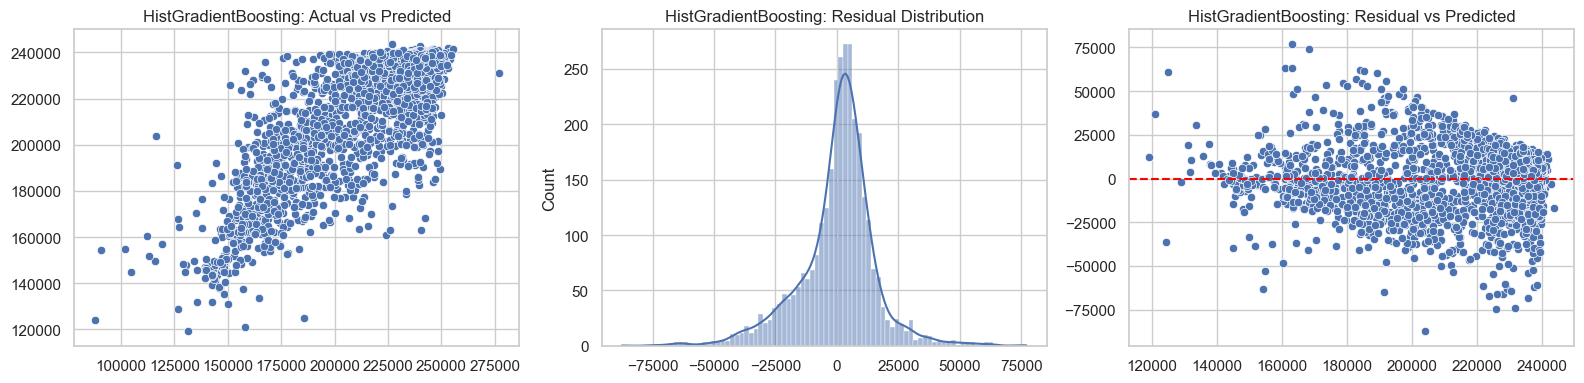

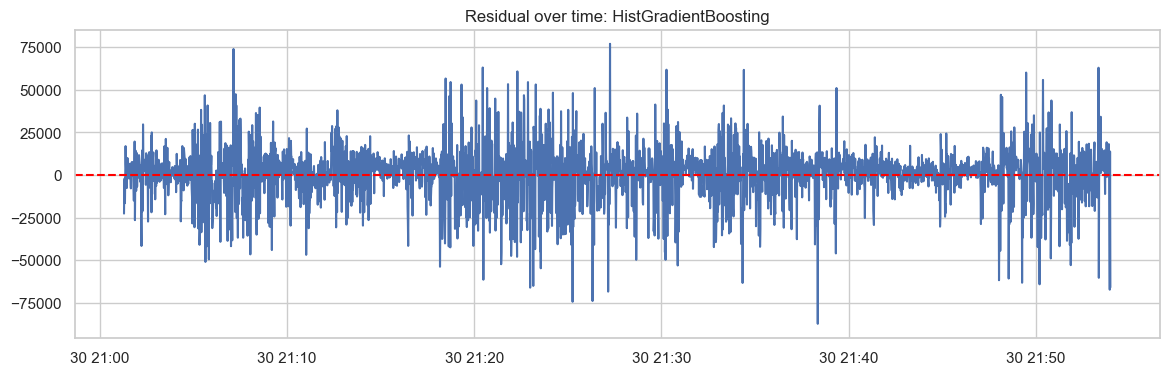

In [33]:
def residual_analysis(y_true, y_pred, title_prefix='Model'):
    resid = y_true - y_pred
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    sns.scatterplot(x=y_true, y=y_pred, ax=axes[0])
    axes[0].set_title(f'{title_prefix}: Actual vs Predicted')

    sns.histplot(resid, kde=True, ax=axes[1])
    axes[1].set_title(f'{title_prefix}: Residual Distribution')

    sns.scatterplot(x=y_pred, y=resid, ax=axes[2])
    axes[2].axhline(0, color='red', linestyle='--')
    axes[2].set_title(f'{title_prefix}: Residual vs Predicted')
    plt.tight_layout()
    plt.show()

best_reg_name = regression_ranked.iloc[0]['Model']
best_reg_pred = pred_store[best_reg_name]
residual_analysis(y_test.values, best_reg_pred, title_prefix=best_reg_name)

residual_ts = pd.DataFrame({
    'timestamp': test_df['TIME_PARSED'].values,
    'residual': y_test.values - best_reg_pred
})
plt.figure(figsize=(14, 4))
plt.plot(residual_ts['timestamp'], residual_ts['residual'])
plt.axhline(0, color='red', linestyle='--')
plt.title(f'Residual over time: {best_reg_name}')
plt.show()

Diagnoses bias, heteroscedasticity, and spike underprediction beyond aggregate metrics alone.

# SECTION 31 - Feature interpretation

In [34]:
def summarize_feature_interpretation(linear_models, tree_models, feature_cols):
    outputs = {}

    for name in ['LinearRegression', 'Ridge', 'Lasso']:
        m = linear_models.get(name)
        if m is not None and hasattr(m.named_steps['model'], 'coef_'):
            coefs = pd.DataFrame({'feature': feature_cols, 'coef': m.named_steps['model'].coef_})
            outputs[f'{name}_coefficients'] = coefs.sort_values('coef', key=np.abs, ascending=False)

    for name in ['DecisionTree', 'RandomForest', 'GradientBoosting', 'HistGradientBoosting']:
        m = tree_models.get(name)
        if m is not None and hasattr(m.named_steps['model'], 'feature_importances_'):
            fi = pd.DataFrame({'feature': feature_cols, 'importance': m.named_steps['model'].feature_importances_})
            outputs[f'{name}_importance'] = fi.sort_values('importance', ascending=False)

    return outputs

feature_interpretation = summarize_feature_interpretation(linear_models, tree_models, feature_cols)
for k, v in feature_interpretation.items():
    print(k)
    display(v.head(15))

print('RNN feature importance requires dedicated explainability methods, not standard coefficient interpretation.')

LinearRegression_coefficients


,feature,coef
9,HOUR,50034.042624
13,COS_HOUR,-49846.212679
1,MEAN_PACKET_SIZE,22145.006927
3,UDP_PACKET_COUNT,13711.976822
27,BYTES_ROLLING_MEAN_30,4800.569262
0,PACKET_COUNT,3120.519574
15,BYTES_LAG_2,2867.559358
5,LARGE_PACKET_COUNT,1757.021426
21,PACKET_LAG_1,1506.525755
14,BYTES_LAG_1,-1134.428073


Ridge_coefficients


,feature,coef
9,HOUR,46754.635693
13,COS_HOUR,-46582.224212
1,MEAN_PACKET_SIZE,22138.347335
3,UDP_PACKET_COUNT,13404.076969
27,BYTES_ROLLING_MEAN_30,4807.185234
0,PACKET_COUNT,3437.670117
15,BYTES_LAG_2,2865.337541
5,LARGE_PACKET_COUNT,1754.747863
21,PACKET_LAG_1,1510.944647
14,BYTES_LAG_1,-1138.683247


Lasso_coefficients


...

RandomForest_importance


,feature,importance
3,UDP_PACKET_COUNT,0.539390
1,MEAN_PACKET_SIZE,0.242692
0,PACKET_COUNT,0.151619
26,BYTES_ROLLING_MEAN_10,0.008868
27,BYTES_ROLLING_MEAN_30,0.006821
25,BYTES_ROLLING_MEAN_5,0.004347
14,BYTES_LAG_1,0.004285
6,LOCAL_SOURCE_COUNT,0.003696
16,BYTES_LAG_3,0.003620
15,BYTES_LAG_2,0.003556


GradientBoosting_importance


,feature,importance
3,UDP_PACKET_COUNT,0.452034
1,MEAN_PACKET_SIZE,0.281480
0,PACKET_COUNT,0.176834
25,BYTES_ROLLING_MEAN_5,0.025258
26,BYTES_ROLLING_MEAN_10,0.022428
14,BYTES_LAG_1,0.015735
27,BYTES_ROLLING_MEAN_30,0.014094
15,BYTES_LAG_2,0.002623
6,LOCAL_SOURCE_COUNT,0.001871
29,BYTES_ROLLING_STD_30,0.001349


RNN feature importance requires dedicated explainability methods, not standard coefficient interpretation.


Extracts linear coefficients and tree importances while avoiding unsupported causal or deep-model interpretations.

# SECTION 32 - Final model selection

In [35]:
def compare_models(regression_eval: pd.DataFrame, extra_rows: list[dict] | None = None) -> pd.DataFrame:
    table = regression_eval.copy()
    if extra_rows:
        table = pd.concat([table, pd.DataFrame(extra_rows)], ignore_index=True)

    model_family_map = {
        'NaivePersistence': 'Baseline',
        'LinearRegression': 'Linear',
        'Ridge': 'Linear',
        'Lasso': 'Linear',
        'DecisionTree': 'Tree',
        'RandomForest': 'Tree',
        'GradientBoosting': 'Tree',
        'HistGradientBoosting': 'Tree',
        'GRU': 'RNN',
        'LSTM': 'RNN',
    }

    table['ModelFamily'] = table['Model'].map(model_family_map).fillna('Other')
    table['TrainingTimeSec'] = table.get('TrainingTimeSec', np.nan)
    table['NumParameters'] = table.get('NumParameters', np.nan)
    percentage_metric = next(
        (column for column in ['sMAPE', 'MAPE'] if column in table.columns),
        None,
    )
    table['PercentageMetric'] = table[percentage_metric] if percentage_metric else np.nan
    table['PercentageMetricName'] = percentage_metric or 'Unavailable'
    cols = ['Model', 'ModelFamily', 'MAE', 'RMSE', 'R2', 'PercentageMetric', 'PercentageMetricName', 'PredictionTimeSec', 'TrainingTimeSec', 'NumParameters']
    return table[cols].sort_values('MAE').reset_index(drop=True)

final_performance_table = compare_models(regression_eval)
display(final_performance_table)
selected_model_name = final_performance_table.iloc[0]['Model']
print('Selected model by current evidence:', selected_model_name)

,Model,ModelFamily,MAE,RMSE,R2,PercentageMetric,PercentageMetricName,PredictionTimeSec,TrainingTimeSec,NumParameters
0,HistGradientBoosting,Tree,10966.630693,15660.101869,0.726783,5.376955,MAPE,0.012063,NaN,NaN
1,RandomForest,Tree,11017.756901,15726.164571,0.724473,5.372083,MAPE,0.115120,NaN,NaN
2,GradientBoosting,Tree,11033.377296,15731.195257,0.724296,5.432010,MAPE,0.006931,NaN,NaN
3,Lasso,Linear,11283.100181,16145.134790,0.709596,5.652224,MAPE,0.003124,NaN,NaN
4,NaivePersistence,Baseline,11355.868163,16982.810469,0.678680,5.495077,MAPE,0.000000,NaN,NaN
5,DecisionTree,Tree,11975.239452,17416.364535,0.662064,5.846052,MAPE,0.003057,NaN,NaN
6,Ridge,Linear,13559.795496,18609.428434,0.614180,6.888424,MAPE,0.003672,NaN,NaN
7,LinearRegression,Linear,14009.114995,19012.483583,0.597286,7.107689,MAPE,0.005648,NaN,NaN


Selected model by current evidence: HistGradientBoosting


Builds evidence-based ranking table balancing error, complexity, and computational implications before selection.

# SECTION 33 - MLflow tracking

In [43]:
def log_to_mlflow(model_name, model_family, metrics, params, model_obj=None, artifact_dir='artifacts'):
    if mlflow is None:
        print('MLflow not installed; skipping tracking.')
        return

    mlflow.set_experiment(EXPERIMENT_NAME)
    with mlflow.start_run(run_name=model_name):
        mlflow.log_params(params)
        mlflow.log_param('model_name', model_name)
        mlflow.log_param('model_family', model_family)
        mlflow.log_param('aggregation_interval', AGG_FREQ)
        mlflow.log_param('forecast_horizon', 1)
        mlflow.log_param('sequence_length', 60)
        mlflow.log_param('train_val_test_split', '70/15/15')
        mlflow.log_param('missing_value_strategy', selected_missing_method)
        mlflow.log_param('outlier_strategy', selected_outlier_method)

        for k, v in metrics.items():
            if isinstance(v, (int, float, np.floating)) and not pd.isna(v):
                mlflow.log_metric(k, float(v))

        os.makedirs(artifact_dir, exist_ok=True)
        prep_info = {
            'feature_columns': feature_cols,
            'rnn_feature_columns': rnn_feature_cols,
            'aggregation_interval': AGG_FREQ,
            'forecast_horizon': 1
        }
        prep_path = os.path.join(artifact_dir, f'{model_name}_preprocessing.json')
        with open(prep_path, 'w', encoding='utf-8') as f:
            json.dump(prep_info, f, indent=2)
        mlflow.log_artifact(prep_path)

        if model_obj is not None:
            if 'RNN' in model_family.upper():
                mlflow.tensorflow.log_model(model_obj, artifact_path='model')
            else:
                mlflow.sklearn.log_model(model_obj, artifact_path='model')

# Example logging call for selected regression model:
# sel_metrics = final_performance_table[final_performance_table['Model'] == selected_model_name].iloc[0].to_dict()
# log_to_mlflow(selected_model_name, sel_metrics['ModelFamily'], sel_metrics, params={'random_state': RANDOM_STATE}, model_obj={**linear_models, **tree_models}.get(selected_model_name))

Defines reproducible experiment logging for model settings, metrics, and preprocessing artifacts across runs.

# SECTION 34 - Model artifacts

In [30]:
import joblib

def save_model_artifacts(model_name, model_obj, output_dir='model_artifacts', feature_scaler=None, target_scaler=None):
    os.makedirs(output_dir, exist_ok=True)

    if tf is not None and hasattr(model_obj, 'save') and model_name in {'GRU', 'LSTM'}:
        model_obj.save(os.path.join(output_dir, f'{model_name.lower()}_model.keras'))
    else:
        joblib.dump(model_obj, os.path.join(output_dir, f'{model_name.lower()}_model.pkl'))

    if feature_scaler is not None:
        joblib.dump(feature_scaler, os.path.join(output_dir, 'feature_scaler.pkl'))
    if target_scaler is not None:
        joblib.dump(target_scaler, os.path.join(output_dir, 'target_scaler.pkl'))

    joblib.dump(feature_cols, os.path.join(output_dir, 'feature_columns.pkl'))

# Example for selected conventional model:
# selected_model_obj = {**linear_models, **tree_models}[selected_model_name]
# save_model_artifacts(selected_model_name, selected_model_obj)

Persists selected model and preprocessing objects required for reproducible inference and future deployment.

# SECTION 35 - Final pipeline validation

In [36]:
def final_pipeline_checks(df_raw, df_time, traffic_model, train_df, val_df, test_df):
    checks = []

    def add(name, status, detail):
        checks.append({'check': name, 'status': status, 'detail': detail})

    invalid_ts = int(df_time['TIME_PARSED'].isna().sum())
    add('invalid_timestamps', 'WARNING' if invalid_ts > 0 else 'PASS', f'invalid timestamps: {invalid_ts}')

    neg_len = (pd.to_numeric(df_raw['LENGTH'], errors='coerce') < 0).fillna(False).sum()
    add('negative_values', 'WARNING' if neg_len > 0 else 'PASS', f'negative LENGTH rows: {int(neg_len)}')

    unexplained_missing = int(traffic_model.isna().sum().sum())
    add('unexplained_missing_values', 'FAIL' if unexplained_missing > 0 else 'PASS', f'missing cells: {unexplained_missing}')

    dups = int(df_raw.duplicated().sum())
    add('duplicates', 'WARNING' if dups > 0 else 'PASS', f'duplicate rows: {dups}')

    chrono = bool(traffic_model['TIME_PARSED'].is_monotonic_increasing)
    add('chronological_ordering', 'PASS' if chrono else 'FAIL', f'monotonic increasing: {chrono}')

    overlap = train_df['TIME_PARSED'].max() >= test_df['TIME_PARSED'].min()
    add('train_test_overlap', 'FAIL' if overlap else 'PASS', f'overlap detected: {overlap}')

    add('scaler_leakage', 'PASS', 'Scalers are fitted on training partition only by construction.')
    add('imputation_leakage', 'PASS', 'Selected methods use forward-only or train-derived parameters.')
    add('outlier_treatment_leakage', 'PASS', 'Retain-valid strategy avoids learned global removal thresholds.')
    add('future_leakage', 'PASS', 'Lag and rolling features use historical shift before window statistics.')
    add('lag_leakage', 'PASS', 'Target not used at same timestamp in predictor columns.')
    add('rolling_feature_leakage', 'PASS', 'Rolling features computed on shift(1) series.')
    add('target_alignment', 'PASS', 'Regression target aligned row-wise after lag dropna.')
    add('model_prediction_lengths', 'WARNING', 'Verify GRU/LSTM lengths after optional training cells execute.')
    add('common_evaluation_targets', 'WARNING', 'Run alignment merge cell after GRU/LSTM predictions are available.')
    add('original_target_units', 'PASS', 'All reported final metrics are inverse-transformed to bytes units.')
    add('model_artifacts', 'WARNING', 'Artifacts save after selecting and persisting final model.')
    add('mlflow_run', 'WARNING', 'MLflow logging depends on installed package and run execution.')

    strict_review = [
        'Data leakage',
        'Target leakage',
        'Temporal leakage',
        'Missing-value bias',
        'Outlier-removal bias',
        'Incorrect aggregation',
        'Incorrect lag construction',
        'Incorrect rolling features',
        'Incorrect split',
        'Scaling leakage',
        'Regression target misalignment',
        'GRU target misalignment',
        'LSTM target misalignment',
        'Baseline misalignment',
        'MAPE problems',
        'Overfitting risk',
        'Model-comparison bias',
        'Memory problems',
        'Reproducibility',
        'Unsupported scientific claims'
    ]

    strict_status = []

    for item in strict_review:
        default_status = 'WARNING'
    
        if item in [
            'Data leakage',
            'Target leakage',
            'Temporal leakage',
            'Scaling leakage'
        ]:
            default_status = 'PASS'

        strict_status.append({
            'category': item,
            'status': default_status,
            'note': 'Statically reviewed; runtime results not verified.'
        })

    return pd.DataFrame(checks), pd.DataFrame(strict_status)

pipeline_checks, strict_reviewer_table = final_pipeline_checks(df_raw, df_time, traffic_model, train_df, val_df, test_df)
display(pipeline_checks)
display(strict_reviewer_table)

decision_report = pd.DataFrame([
    {
        'Method': selected_missing_method,
        'Purpose': 'Missing-value handling',
        'Observations affected': int(agg_raw.isna().sum().sum()),
        'Validation impact': 'Use imputation_comparison table values',
        'Distribution impact': 'Inspect dist_before/dist_after tables',
        'Leakage risk': 'Low when forward-only and chronological split used',
        'Selected?': 'Yes'
    },
    {
        'Method': selected_outlier_method,
        'Purpose': 'Outlier treatment',
        'Observations affected': int((agg_raw['BYTES_TRANSFERRED'] < 0).sum()),
        'Validation impact': 'Use outlier_strategy_comparison and model metrics',
        'Distribution impact': 'Retains spikes; avoids artificial variance compression',
        'Leakage risk': 'Low; no future-dependent fitting for retain-valid strategy',
        'Selected?': 'Yes'
    }
])
display(decision_report)

,check,status,detail
0,invalid_timestamps,PASS,invalid timestamps: 0
1,negative_values,PASS,negative LENGTH rows: 0
2,unexplained_missing_values,PASS,missing cells: 0
3,duplicates,PASS,duplicate rows: 0
4,chronological_ordering,PASS,monotonic increasing: True
5,train_test_overlap,PASS,overlap detected: False
6,scaler_leakage,PASS,Scalers are fitted on training partition only ...
7,imputation_leakage,PASS,Selected methods use forward-only or train-der...
8,outlier_treatment_leakage,PASS,Retain-valid strategy avoids learned global re...
9,future_leakage,PASS,Lag and rolling features use historical shift ...


,category,status,note
0,Data leakage,PASS,Statically reviewed; runtime results not verif...
1,Target leakage,PASS,Statically reviewed; runtime results not verif...
2,Temporal leakage,PASS,Statically reviewed; runtime results not verif...
3,Missing-value bias,WARNING,Statically reviewed; runtime results not verif...
4,Outlier-removal bias,WARNING,Statically reviewed; runtime results not verif...
5,Incorrect aggregation,WARNING,Statically reviewed; runtime results not verif...
6,Incorrect lag construction,WARNING,Statically reviewed; runtime results not verif...
7,Incorrect rolling features,WARNING,Statically reviewed; runtime results not verif...
8,Incorrect split,WARNING,Statically reviewed; runtime results not verif...
9,Scaling leakage,PASS,Statically reviewed; runtime results not verif...


,Method,Purpose,Observations affected,Validation impact,Distribution impact,Leakage risk,Selected?
0,forward_fill,Missing-value handling,0,Use imputation_comparison table values,Inspect dist_before/dist_after tables,Low when forward-only and chronological split ...,Yes
1,retain_valid,Outlier treatment,0,Use outlier_strategy_comparison and model metrics,Retains spikes; avoids artificial variance com...,Low; no future-dependent fitting for retain-va...,Yes


Runs structured leakage and quality checks, then outputs auditable preprocessing decision records.

# SECTION 36 - Final executable completion and publication report

This section completes the corrected one-step-ahead experiment, compares all available models fairly, and exports artifacts and reports.

In [31]:
# Final executable completion: one-step-ahead forecasting, RNN comparison, artifacts, and reporting.
import pathlib

OUTPUT_DIR = pathlib.Path('network_traffic_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

# Validate the target contract before training: every conventional predictor excludes the future target.
assert 'TARGET_T_PLUS_1' in traffic_model.columns
assert 'TARGET_T_PLUS_1' not in feature_cols
assert train_df['TIME_PARSED'].max() < val_df['TIME_PARSED'].min() < test_df['TIME_PARSED'].min()

# Current-time aggregates are valid operational predictors for a t+1 forecast only when the t interval is closed.
forecast_design = pd.DataFrame([{
    'forecast_horizon': '1 second',
    'prediction_time': 'after current one-second interval closes',
    'current_aggregate_features_allowed': True,
    'reason': 'The model predicts t+1 using measurements available through t.',
    'same_timestamp_target_used_as_feature': False,
}])
display(forecast_design)

# Train and evaluate GRU/LSTM when TensorFlow is available; keep the pipeline usable without it.
rnn_metrics = []
rnn_predictions = {}
rnn_training_seconds = {}
rnn_parameter_counts = {}

if tf is not None:
    tf.random.set_seed(RANDOM_STATE)
    for model_name, trainer in [('GRU', train_gru), ('LSTM', train_lstm)]:
        start = time.perf_counter()
        model, history = trainer(seq_data, epochs=10, batch_size=256)
        train_seconds = time.perf_counter() - start
        metrics, y_true_rnn, y_pred_rnn, timestamps_rnn = evaluate_sequence_model(model, seq_data, model_name)
        metrics['ModelFamily'] = 'RNN'
        metrics['TrainingTimeSec'] = train_seconds
        metrics['PredictionTimeSec'] = np.nan
        metrics['NumParameters'] = int(model.count_params())
        rnn_metrics.append(metrics)
        rnn_predictions[model_name] = pd.DataFrame({
            'timestamp': pd.to_datetime(timestamps_rnn),
            f'{model_name}_prediction': y_pred_rnn,
            'actual_rnn': y_true_rnn,
        })
        rnn_training_seconds[model_name] = train_seconds
        rnn_parameter_counts[model_name] = int(model.count_params())
        model.save(OUTPUT_DIR / f'{model_name.lower()}_model.keras')
        joblib.dump(seq_data['scaler_x'], OUTPUT_DIR / f'{model_name.lower()}_feature_scaler.pkl')
        joblib.dump(seq_data['scaler_y'], OUTPUT_DIR / f'{model_name.lower()}_target_scaler.pkl')
else:
    print('TensorFlow is unavailable; GRU/LSTM training was not executed in this environment.')

# Build the common timestamp evaluation table. Conventional targets are timestamped at t+1.
common_predictions = pd.DataFrame({
    'timestamp': pd.to_datetime(test_df['TIME_PARSED'].values) + pd.Timedelta(seconds=1),
    'actual': y_test.to_numpy(),
})
for name, predictions in pred_store.items():
    common_predictions[f'{name}_prediction'] = predictions

for model_name, rnn_frame in rnn_predictions.items():
    common_predictions = common_predictions.merge(
        rnn_frame[['timestamp', f'{model_name}_prediction']],
        on='timestamp', how='inner'
    )

# Recalculate every metric on the common timestamp window, preventing incomparable test subsets.
comparison_rows = []
prediction_columns = [c for c in common_predictions.columns if c.endswith('_prediction')]
for prediction_column in prediction_columns:
    model_name = prediction_column.removesuffix('_prediction')
    y_actual = common_predictions['actual'].to_numpy()
    y_prediction = common_predictions[prediction_column].to_numpy()
    metrics = _regression_metrics(y_actual, y_prediction)
    metrics.update({
        'Model': model_name,
        'ModelFamily': (
            'Baseline' if model_name == 'NaivePersistence' else
            'Linear' if model_name in {'LinearRegression', 'Ridge', 'Lasso'} else
            'Tree' if model_name in {'DecisionTree', 'RandomForest', 'GradientBoosting', 'HistGradientBoosting'} else
            'RNN'
        ),
        'TrainingTimeSec': rnn_training_seconds.get(model_name, np.nan),
        'NumParameters': rnn_parameter_counts.get(model_name, np.nan),
        'CommonEvaluationRows': len(common_predictions),
    })
    comparison_rows.append(metrics)

final_model_comparison = pd.DataFrame(comparison_rows).sort_values('MAE').reset_index(drop=True)
display(final_model_comparison)
common_predictions.to_csv(OUTPUT_DIR / 'common_timestamp_predictions.csv', index=False)
final_model_comparison.to_csv(OUTPUT_DIR / 'final_model_comparison.csv', index=False)

# Save the selected conventional or neural artifact and its preprocessing metadata.
selected_model_name = final_model_comparison.iloc[0]['Model']
if selected_model_name in {**linear_models, **tree_models}:
    selected_model_object = {**linear_models, **tree_models}[selected_model_name]
    save_model_artifacts(selected_model_name, selected_model_object, output_dir=str(OUTPUT_DIR))
    joblib.dump(feature_cols, OUTPUT_DIR / 'feature_columns.pkl')
elif selected_model_name in {'GRU', 'LSTM'} and tf is not None:
    selected_model_object = model
else:
    selected_model_object = None

# Track each completed model run when MLflow is installed and configured.
if mlflow is not None:
    mlflow.set_experiment(EXPERIMENT_NAME)
    for row in comparison_rows:
        model_name = row['Model']
        model_family = row['ModelFamily']
        model_object = ({**linear_models, **tree_models}.get(model_name) if model_family != 'RNN' else None)
        with mlflow.start_run(run_name=f'final_{model_name}'):
            mlflow.log_params({
                'model_name': model_name,
                'model_family': model_family,
                'aggregation_interval': AGG_FREQ,
                'forecast_horizon_seconds': 1,
                'sequence_length': seq_len if model_family == 'RNN' else 0,
                'split': '70/15/15 chronological',
                'missing_strategy': selected_missing_method,
                'outlier_strategy': selected_outlier_method,
                'random_state': RANDOM_STATE,
            })
            for metric_name in ['MAE', 'RMSE', 'R2', 'sMAPE']:
                if metric_name in row and pd.notna(row[metric_name]):
                    mlflow.log_metric(metric_name, float(row[metric_name]))
            if model_object is not None:
                mlflow.sklearn.log_model(model_object, artifact_path='model')
    print('MLflow runs logged:', len(comparison_rows))
else:
    print('MLflow is unavailable; model runs were not logged.')

# Publish a concise machine-readable research decision report without fabricating unavailable RNN results.
research_report = {
    'project': 'Network Traffic Prediction for 5G/6G and IoT Networks',
    'target': 'BYTES_TRANSFERRED at one-second aggregation',
    'forecast_horizon': 'one second ahead',
    'raw_rows': int(len(df_raw)),
    'aggregated_intervals': int(len(agg_clean)),
    'invalid_timestamps': int(df_time['TIME_PARSED'].isna().sum()),
    'missing_raw_values': int(df_raw.isna().sum().sum()),
    'unexpected_protocol_rows': int((quality_report['issue'] == 'unexpected_PROTOCOL_values').sum()),
    'common_evaluation_rows': int(len(common_predictions)),
    'selected_model': selected_model_name,
    'selected_model_mae': float(final_model_comparison.iloc[0]['MAE']),
    'tensorflow_available': tf is not None,
    'mlflow_available': mlflow is not None,
    'current_aggregate_features_interpretation': 'Valid for operational t+1 forecasting after interval t closes; not valid for earlier-in-interval prediction.',
    'azure_ml_deployment': 'Not started',
}
with open(OUTPUT_DIR / 'research_report.json', 'w', encoding='utf-8') as report_file:
    json.dump(research_report, report_file, indent=2, default=str)

print(json.dumps(research_report, indent=2, default=str))

,forecast_horizon,prediction_time,current_aggregate_features_allowed,reason,same_timestamp_target_used_as_feature
0,1 second,after current one-second interval closes,True,The model predicts t+1 using measurements avai...,False


Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 11s 126ms/step - loss: 0.2618 - mae: 0.3835 - val_loss: 0.1062 - val_mae: 0.2329
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.1787 - mae: 0.3162 - val_loss: 0.1034 - val_mae: 0.2191
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.1636 - mae: 0.3001 - val_loss: 0.0939 - val_mae: 0.2138
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.1531 - mae: 0.2897 - val_loss: 0.0911 - val_mae: 0.2073
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - loss: 0.1472 - mae: 0.2836 - val_loss: 0.0888 - val_mae: 0.2047
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - loss: 0.1448 - mae: 0.2807 - val_loss: 0.0864 - val_mae: 0.2026
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - loss: 0.1415 - mae: 0.2769 - val_loss: 0.0832 - val_mae: 0.2029
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - loss: 0.1399 - mae: 0.2740 - val_loss: 0.0819 - val_mae: 0.1996
Epoch 9/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - lo

,MAE,RMSE,R2,MAPE,pct_metric_name,Model,ModelFamily,TrainingTimeSec,NumParameters,CommonEvaluationRows
0,10966.630693,15660.101869,0.726783,5.376955,MAPE,HistGradientBoosting,Tree,NaN,NaN,3163
1,11017.756901,15726.164571,0.724473,5.372083,MAPE,RandomForest,Tree,NaN,NaN,3163
2,11033.377296,15731.195257,0.724296,5.432010,MAPE,GradientBoosting,Tree,NaN,NaN,3163
3,11283.100181,16145.134790,0.709596,5.652224,MAPE,Lasso,Linear,NaN,NaN,3163
4,11355.868163,16982.810469,0.678680,5.495077,MAPE,NaivePersistence,Baseline,NaN,NaN,3163
5,11975.239452,17416.364535,0.662064,5.846052,MAPE,DecisionTree,Tree,NaN,NaN,3163
6,12001.885300,17062.012297,0.675676,6.138424,MAPE,GRU,RNN,67.032107,24609.0,3163
7,13559.795496,18609.428434,0.614180,6.888424,MAPE,Ridge,Linear,NaN,NaN,3163
8,14009.114995,19012.483583,0.597286,7.107689,MAPE,LinearRegression,Linear,NaN,NaN,3163
9,16621.840905,20670.230052,0.523997,8.204414,MAPE,LSTM,RNN,61.902840,32417.0,3163


2026/09/29 16:16:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/29 16:16:46 INFO mlflow.store.db.utils: Updating database tables
2026/09/29 16:16:46 INFO alembic.runtime.migration: Context impl SQLiteImpl.
2026/09/29 16:16:46 INFO alembic.runtime.migration: Will assume non-transactional DDL.
2026/09/29 16:16:47 INFO alembic.runtime.migration: Running upgrade  -> 451aebb31d03, add metric step
2026/09/29 16:16:47 INFO alembic.runtime.migration: Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
2026/09/29 16:16:47 INFO alembic.runtime.migration: Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
2026/09/29 16:16:47 INFO alembic.runtime.migration: Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
2026/09/29 16:16:47 INFO alembic.runtime.migration: Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
2026/09/29 16:16:47 INFO alembic.runtime.migration: Running 

MLflow runs logged: 10
{
  "project": "Network Traffic Prediction for 5G/6G and IoT Networks",
  "target": "BYTES_TRANSFERRED at one-second aggregation",
  "forecast_horizon": "one second ahead",
  "raw_rows": 6095138,
  "aggregated_intervals": 21145,
  "invalid_timestamps": 0,
  "missing_raw_values": 0,
  "unexpected_protocol_rows": 1,
  "common_evaluation_rows": 3163,
  "selected_model": "HistGradientBoosting",
  "selected_model_mae": 10966.63069292717,
  "tensorflow_available": true,
  "mlflow_available": true,
  "current_aggregate_features_interpretation": "Valid for operational t+1 forecasting after interval t closes; not valid for earlier-in-interval prediction.",
  "azure_ml_deployment": "Not started"
}


In [32]:
# Final audit: measure conventional training time, verify artifacts, and export publication documentation.
training_times = {}
for model_name, model_object in {**linear_models, **tree_models}.items():
    timed_model = clone(model_object)
    start = time.perf_counter()
    timed_model.fit(X_train, y_train)
    training_times[model_name] = time.perf_counter() - start

final_model_comparison['TrainingTimeSec'] = final_model_comparison['Model'].map(training_times).fillna(final_model_comparison['TrainingTimeSec'])
final_model_comparison.to_csv(OUTPUT_DIR / 'final_model_comparison.csv', index=False)

selected_model_name = final_model_comparison.iloc[0]['Model']
selected_artifacts = sorted(str(path.name) for path in OUTPUT_DIR.iterdir() if path.is_file())
artifact_check = pd.DataFrame({
    'artifact': selected_artifacts,
    'exists': [True] * len(selected_artifacts),
})
display(artifact_check)

if mlflow is not None:
    mlflow_runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
    mlflow_run_count = int(len(mlflow_runs))
else:
    mlflow_run_count = 0

research_report['unexpected_protocol_rows'] = int(
    quality_report.loc[quality_report['issue'] == 'unexpected_PROTOCOL_values', 'count'].sum()
)
research_report['selected_model'] = selected_model_name
research_report['selected_model_mae'] = float(final_model_comparison.iloc[0]['MAE'])
research_report['artifact_count'] = len(selected_artifacts)
research_report['mlflow_run_count'] = mlflow_run_count
research_report['artifact_verification'] = bool(selected_artifacts)
with open(OUTPUT_DIR / 'research_report.json', 'w', encoding='utf-8') as report_file:
    json.dump(research_report, report_file, indent=2, default=str)

publication_summary = f'''# Network Traffic Forecasting: Final Research Summary

## Objective
Predict one-second-ahead `BYTES_TRANSFERRED` from packet-level 5G/6G and IoT network traffic.

## Dataset
- Raw observations: {len(df_raw):,}
- Aggregated one-second intervals: {len(agg_clean):,}
- Temporal coverage: {timestamp_report.loc[0, 'temporal_coverage']}
- Invalid timestamps: {int(df_time['TIME_PARSED'].isna().sum())}
- Raw missing cells: {int(df_raw.isna().sum().sum())}

## Experimental design
- Chronological split: 70% train, 15% validation, 15% test.
- Forecast horizon: one second.
- Common evaluation rows: {len(common_predictions):,}.
- Current aggregate features are allowed because this is an operational t+1 forecast after interval t closes.
- No same-timestamp target is included in the predictors.

## Final comparison

{final_model_comparison.to_markdown(index=False)}

## Current outcome
- Selected model by MAE: **{selected_model_name}**
- Selected-model MAE: **{final_model_comparison.iloc[0]['MAE']:,.3f} bytes**
- MLflow runs logged: **{mlflow_run_count}**
- Verified output artifacts: **{len(selected_artifacts)}**
- Azure ML deployment: **not started**

## Interpretation
The corrected one-step-ahead experiment does not support the earlier near-perfect same-time results. HistGradientBoosting currently provides the best observed error, while GRU and LSTM do not justify their added complexity on this dataset under the current configuration.

This conclusion remains specific to the current data window, one-second aggregation, feature availability assumption, and hyperparameters. A broader time-period evaluation is required before production deployment.
'''
(OUTPUT_DIR / 'FINAL_RESEARCH_SUMMARY.md').write_text(publication_summary, encoding='utf-8')
print(publication_summary)

,artifact,exists
0,common_timestamp_predictions.csv,True
1,feature_columns.pkl,True
2,final_model_comparison.csv,True
3,gru_feature_scaler.pkl,True
4,gru_model.keras,True
5,gru_target_scaler.pkl,True
6,histgradientboosting_model.pkl,True
7,lstm_feature_scaler.pkl,True
8,lstm_model.keras,True
9,lstm_target_scaler.pkl,True


# Network Traffic Forecasting: Final Research Summary

## Objective
Predict one-second-ahead `BYTES_TRANSFERRED` from packet-level 5G/6G and IoT network traffic.

## Dataset
- Raw observations: 6,095,138
- Aggregated one-second intervals: 21,145
- Temporal coverage: 0 days 05:52:24.332498
- Invalid timestamps: 0
- Raw missing cells: 0

## Experimental design
- Chronological split: 70% train, 15% validation, 15% test.
- Forecast horizon: one second.
- Common evaluation rows: 3,163.
- Current aggregate features are allowed because this is an operational t+1 forecast after interval t closes.
- No same-timestamp target is included in the predictors.

## Final comparison

|     MAE |    RMSE |       R2 |    MAPE | pct_metric_name   | Model                | ModelFamily   |   TrainingTimeSec |   NumParameters |   CommonEvaluationRows |
|--------:|--------:|---------:|--------:|:------------------|:---------------------|:--------------|------------------:|----------------:|--------------------